In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder


In [7]:
#load the dataset
df = pd.read_csv('bmi.csv')

In [ ]:
# Basic info
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Gender  500 non-null    object
 1   Height  500 non-null    int64 
 2   Weight  500 non-null    int64 
 3   Index   500 non-null    int64 
dtypes: int64(3), object(1)
memory usage: 15.8+ KB
None


In [8]:
df.head()


,Gender,Height,Weight,Index
0,Male,174,96,4
1,Male,189,87,2
2,Female,185,110,4
3,Female,195,104,3
4,Male,149,61,3


This data frame contains the following columns:

Gender : Male / Female\
Height : Number (cm)\
Weight : Number (Kg)
Index :
*   0 - Severely Underweight
*   1 - Underweight

*   2 - Normal
*   3 - Overweight

*   4 - Obesity
*   5 - Severely Obesity












In [9]:
# Data Exploration
print(df.describe())

           Height      Weight       Index
count  500.000000  500.000000  500.000000
mean   169.944000  106.000000    3.748000
std     16.375261   32.382607    1.355053
min    140.000000   50.000000    0.000000
25%    156.000000   80.000000    3.000000
50%    170.500000  106.000000    4.000000
75%    184.000000  136.000000    5.000000
max    199.000000  160.000000    5.000000


In [10]:
print(df.isnull().sum())  # Check for missing values

Gender    0
Height    0
Weight    0
Index     0
dtype: int64


In [11]:
# Detect outliers using IQR method
Q1 = df[['Height', 'Weight']].quantile(0.25)
Q3 = df[['Height', 'Weight']].quantile(0.75)
IQR = Q3 - Q1
outliers = ((df[['Height', 'Weight']] < (Q1 - 1.5 * IQR)) | (df[['Height', 'Weight']] > (Q3 + 1.5 * IQR)))
print("Outliers detected:")
print(df[outliers.any(axis=1)])

Outliers detected:
Empty DataFrame
Columns: [Gender, Height, Weight, Index]
Index: []


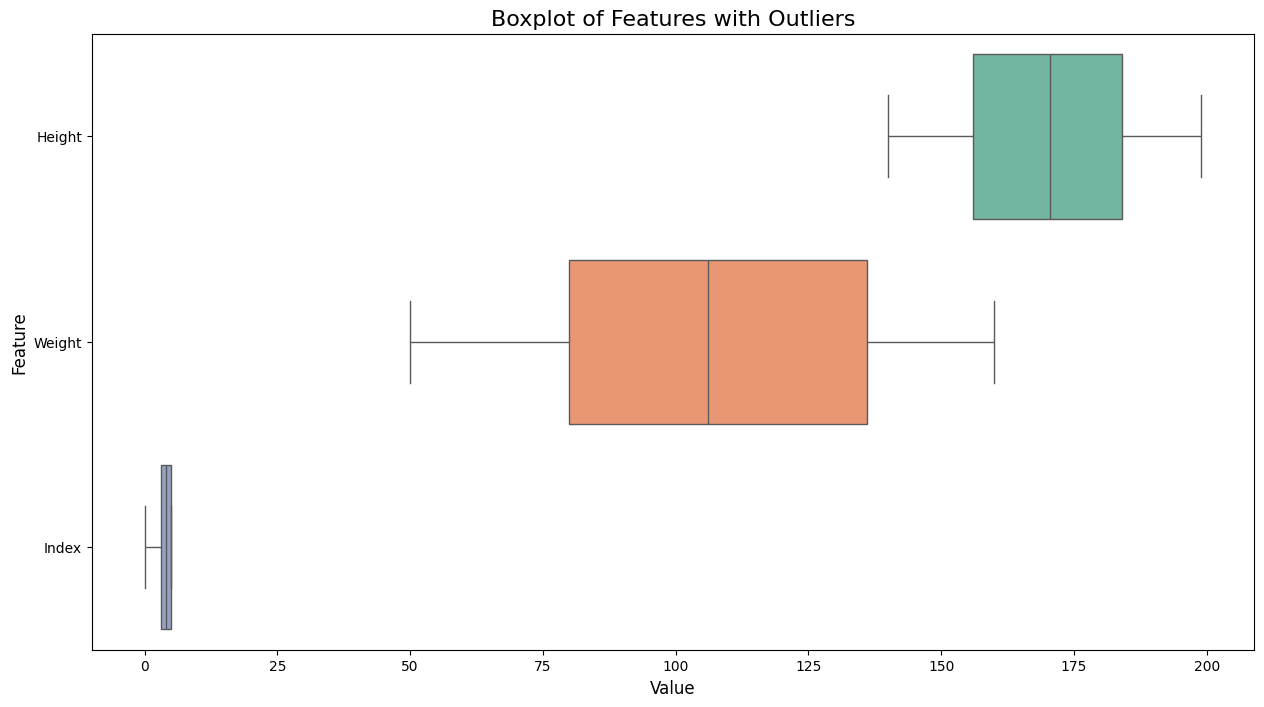

In [12]:
# Boxplot visualization of outliers
numeric_cols = df.select_dtypes(include=['number']).columns
plt.figure(figsize=(15, 8))
sns.boxplot(data=df[numeric_cols], orient='h', palette='Set2')
plt.title('Boxplot of Features with Outliers', fontsize=16)
plt.xlabel('Value', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.show()

In [14]:
#BMI category Distrbution in the dataset
print("BMI Category Distribution:")
print(df['Index'].value_counts())


BMI Category Distribution:
Index
5    198
4    130
2     69
3     68
1     22
0     13
Name: count, dtype: int64


<ipython-input-15-854fbab7daf3>:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Gender', fontsize=12)


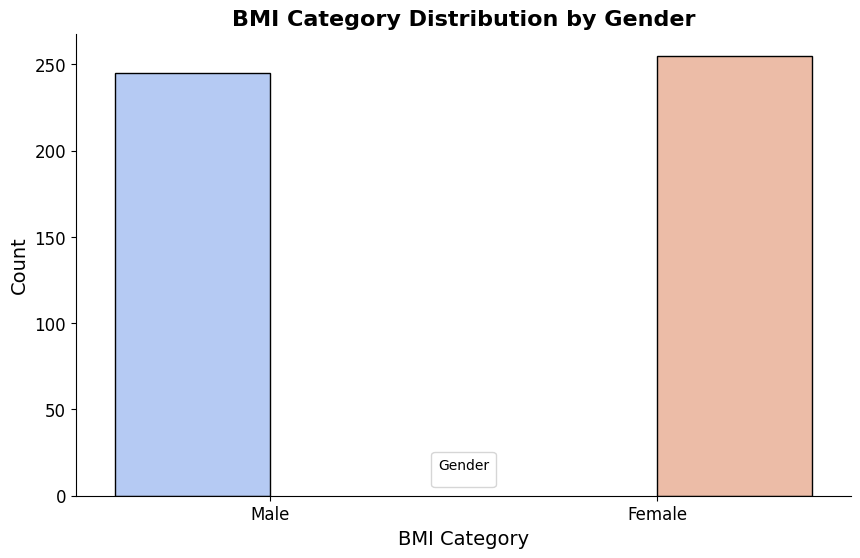

In [15]:
# Count distribution of BMI categories based on Gender
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='Gender', hue='Gender', palette='coolwarm', dodge=True, edgecolor='black')
plt.title('BMI Category Distribution by Gender', fontsize=16, fontweight='bold')
plt.xlabel('BMI Category', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(title='Gender', fontsize=12)
sns.despine()
plt.show()

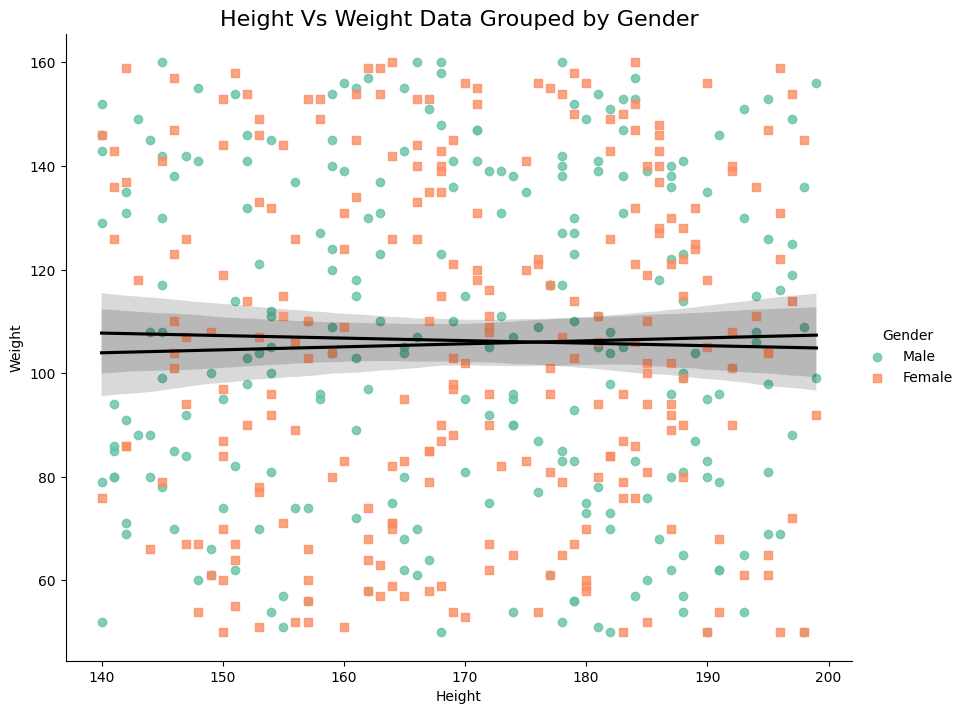

In [16]:
#Height Vs Weight Data Grouped by Gender
sns.lmplot(x='Height', y='Weight', hue='Gender', data=df,
           fit_reg=True, height=7, aspect=1.25,
           palette="Set2", markers=["o", "s"], line_kws={"color": "black"})
ax = plt.gca()
ax.set_title("Height Vs Weight Data Grouped by Gender", fontsize=16)
plt.show()


As we see the data points are randomly scattered without forming a recognizable trend.So, we can hypothesize that gender does not affect the index/BMI value significantly.

<ipython-input-17-ec7894fd1300>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Index', data=df, palette='Set2')


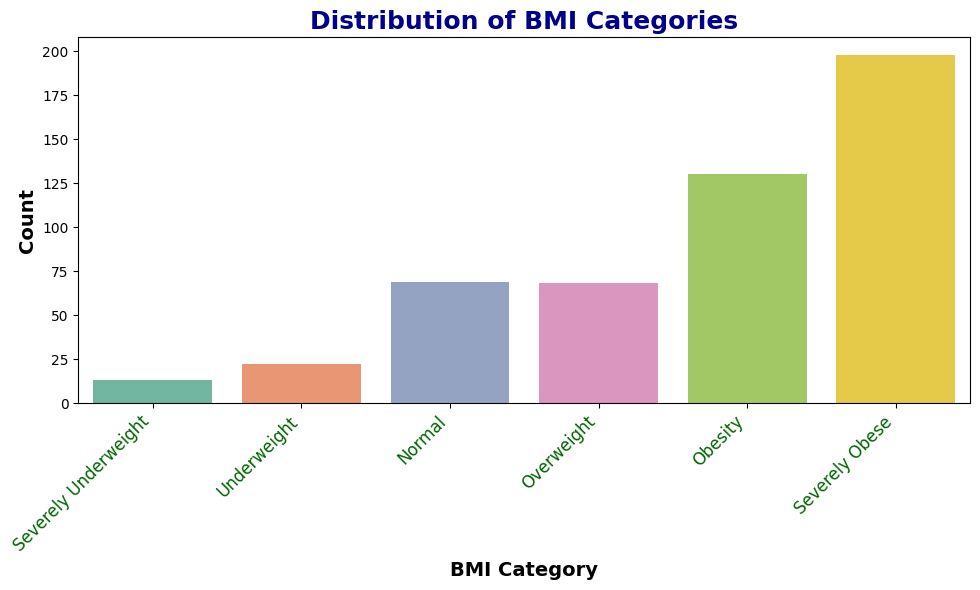

In [17]:
# Plot BMI category distribution with improved alignment and spacing
plt.figure(figsize=(10, 6))  # Increased the figure size for better alignment
sns.countplot(x='Index', data=df, palette='Set2')
plt.title('Distribution of BMI Categories', fontsize=18, fontweight='bold', color='darkblue')
plt.xlabel('BMI Category', fontsize=14, fontweight='bold', color='black')
plt.ylabel('Count', fontsize=14, fontweight='bold', color='black')
plt.xticks(ticks=[0, 1, 2, 3, 4, 5],
           labels=['Severely Underweight', 'Underweight', 'Normal', 'Overweight', 'Obesity', 'Severely Obese'],
           fontsize=12, rotation=45, ha='right', color='darkgreen')

plt.tight_layout()
plt.show()


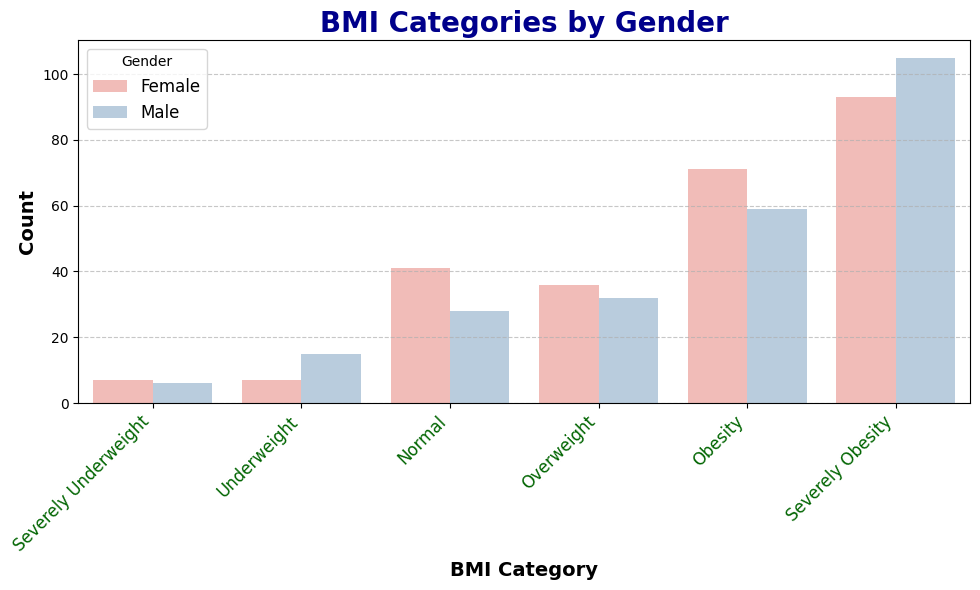

In [18]:
# Plot BMI categories by Gender
plt.figure(figsize=(10, 6))
sns.countplot(x='Index', hue='Gender', data=df, palette='Pastel1')
plt.title('BMI Categories by Gender', fontsize=20, fontweight='bold', color='darkblue')
plt.xlabel('BMI Category', fontsize=14, fontweight='bold', color='black')
plt.ylabel('Count', fontsize=14, fontweight='bold', color='black')
plt.xticks(ticks=[0, 1, 2, 3, 4, 5],
           labels=['Severely Underweight', 'Underweight', 'Normal', 'Overweight', 'Obesity', 'Severely Obesity'],
           fontsize=12, rotation=45, ha='right', color='darkgreen')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='Gender', loc='upper left', fontsize=12)
plt.tight_layout()
plt.show()


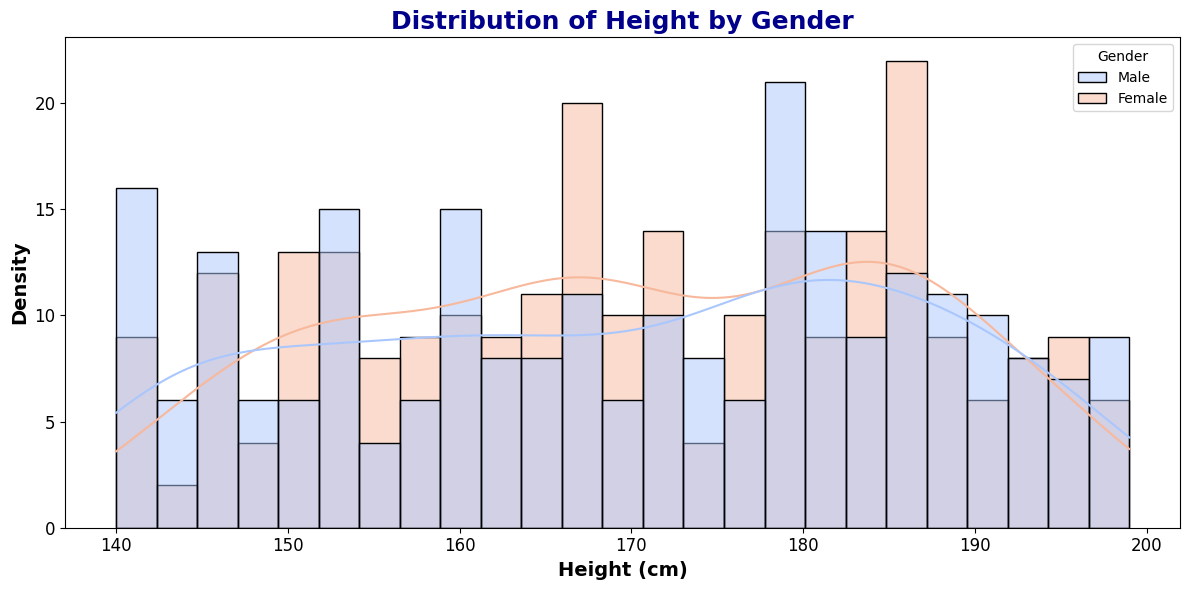

In [19]:
# Distribution of Height by Gender
plt.figure(figsize=(12, 6))
sns.histplot(data=df, x='Height', hue='Gender', kde=True, bins=25, palette='coolwarm')
plt.title('Distribution of Height by Gender', fontsize=18, fontweight='bold', color='darkblue')
plt.xlabel('Height (cm)', fontsize=14, fontweight='bold', color='black')
plt.ylabel('Density', fontsize=14, fontweight='bold', color='black')
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()


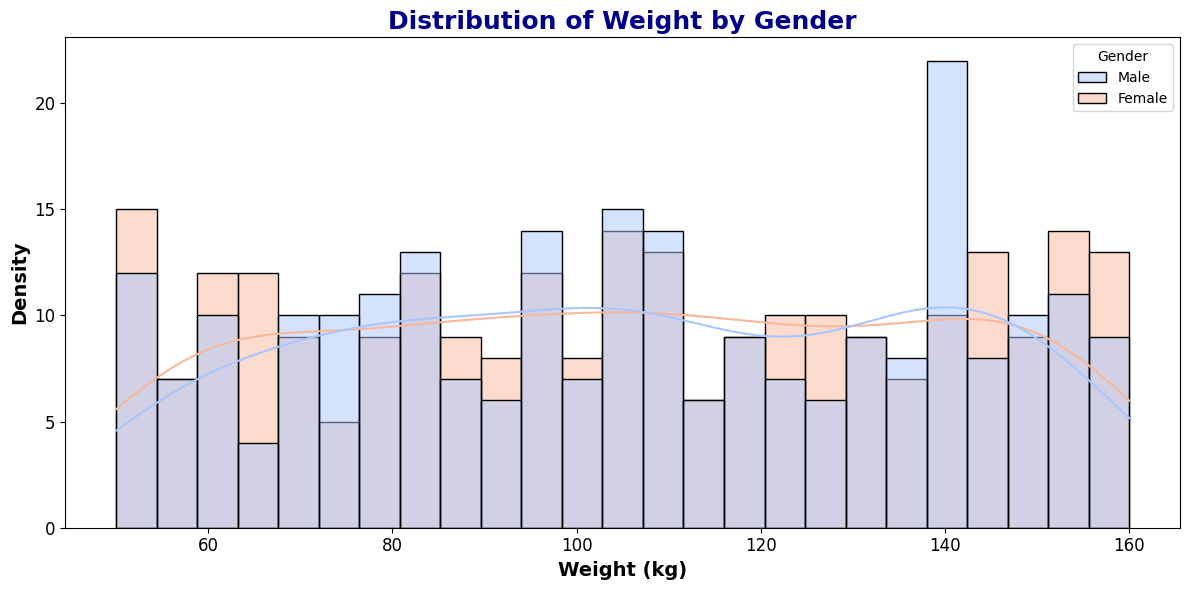

In [20]:
 # Distribution of Weight by Gender
plt.figure(figsize=(12, 6))
sns.histplot(data=df, x='Weight', hue='Gender', kde=True, bins=25, palette='coolwarm')
plt.title('Distribution of Weight by Gender', fontsize=18, fontweight='bold', color='darkblue')
plt.xlabel('Weight (kg)', fontsize=14, fontweight='bold', color='black')
plt.ylabel('Density', fontsize=14, fontweight='bold', color='black')
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()


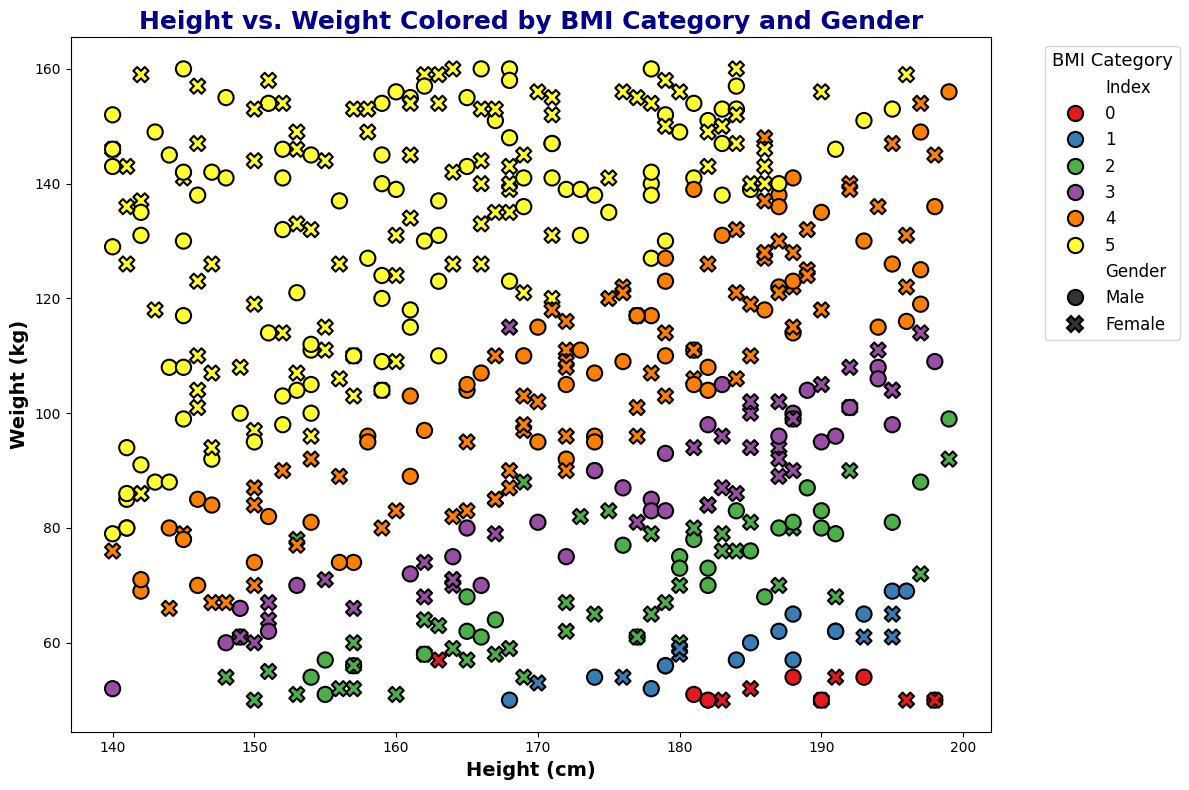

In [21]:
#Height vs. Weight Colored by BMI Category and Gender
plt.figure(figsize=(12, 8))
sns.scatterplot(data=df, x='Height', y='Weight', hue='Index', style='Gender', palette='Set1', s=120, edgecolor='black', linewidth=1.5)
plt.title('Height vs. Weight Colored by BMI Category and Gender', fontsize=18, fontweight='bold', color='darkblue')
plt.xlabel('Height (cm)', fontsize=14, fontweight='bold', color='black')
plt.ylabel('Weight (kg)', fontsize=14, fontweight='bold', color='black')
plt.legend(title='BMI Category', title_fontsize='13', loc='upper left', bbox_to_anchor=(1.05, 1), fontsize=12)
plt.tight_layout()
plt.show()


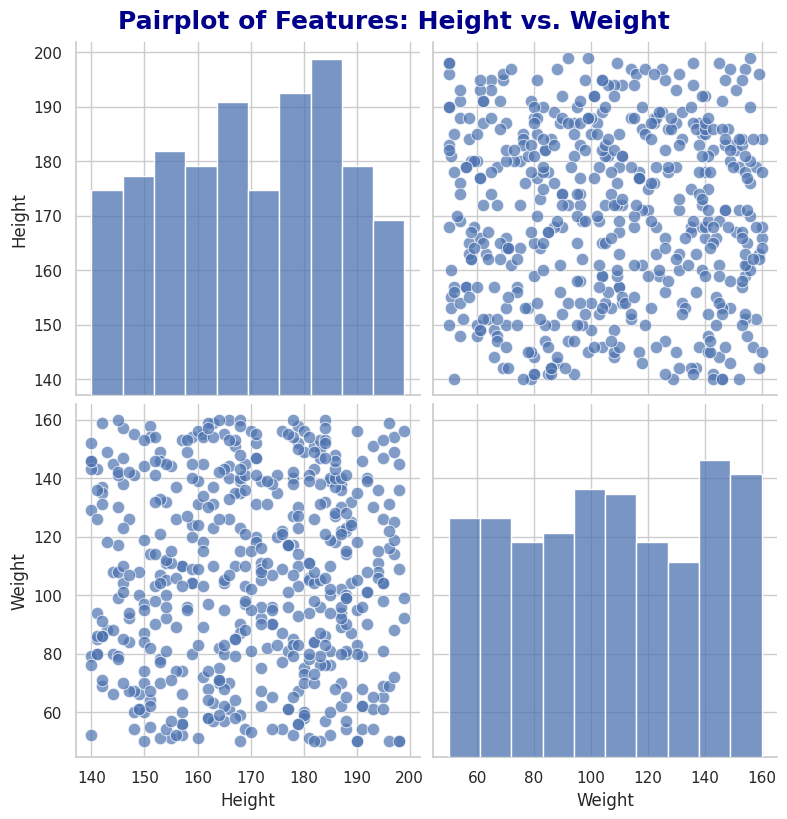

In [22]:
# Pairplot
sns.set(style="whitegrid")
sns.pairplot(df[['Height', 'Weight']], kind='scatter', plot_kws={'s': 80, 'alpha': 0.7}, height=4)
plt.suptitle('Pairplot of Features: Height vs. Weight', y=1.02, fontsize=18, fontweight='bold', color='darkblue')
plt.show()

In [23]:
#Group the data by 'Gender' and 'Index' (BMI category) to calculate average 'Height' and 'Weight'
grouped_data = df.groupby(['Gender', 'Index'])[['Height', 'Weight']].mean()
summary_stats = grouped_data.reset_index()
summary_stats.rename(columns={'Height': 'Average Height (cm)', 'Weight': 'Average Weight (kg)'}, inplace=True)
summary_stats


,Gender,Index,Average Height (cm),Average Weight (kg)
0,Female,0,186.571429,51.857143
1,Female,1,184.142857,58.714286
2,Female,2,171.682927,66.926829
3,Female,3,176.944444,87.722222
4,Female,4,174.338028,108.070423
5,Female,5,161.569892,135.526882
6,Male,0,188.666667,51.500000
7,Male,1,185.066667,59.733333
8,Male,2,178.035714,72.250000
9,Male,3,174.906250,85.937500


Text(0.5, 1.0, 'Relationship Between Height and Weight Grouped by BMI Category')

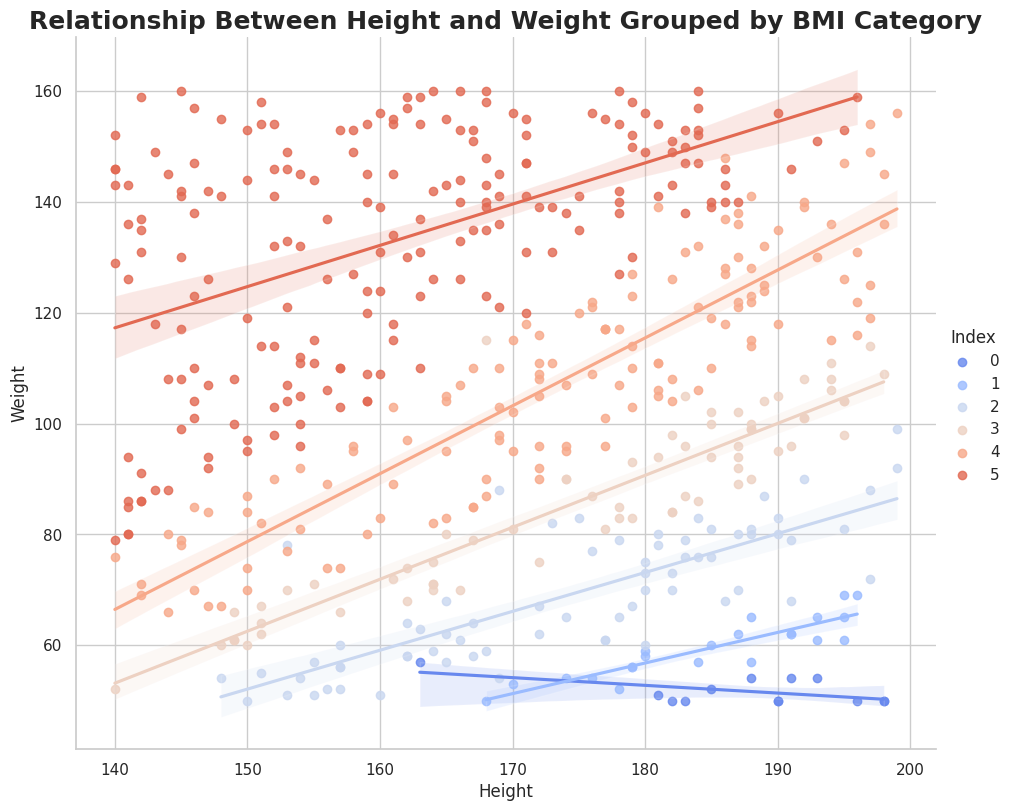

In [24]:
sns.lmplot(x='Height', y='Weight', hue='Index', data=df,
           fit_reg=True, height=8, aspect=1.2, palette='coolwarm')
ax = plt.gca()
ax.set_title("Relationship Between Height and Weight Grouped by BMI Category", fontsize=18, fontweight='bold')


Distinct patterns can be observed in the data based on the index value.

This indicates a general positive correlation between height and weight within each BMI category.

Next, let's explore whether there are any variations in this relationship when the data is analyzed separately for each gender.

Text(0.5, 1.0, 'Female Height Vs Weight Data Grouped by BMI Category')

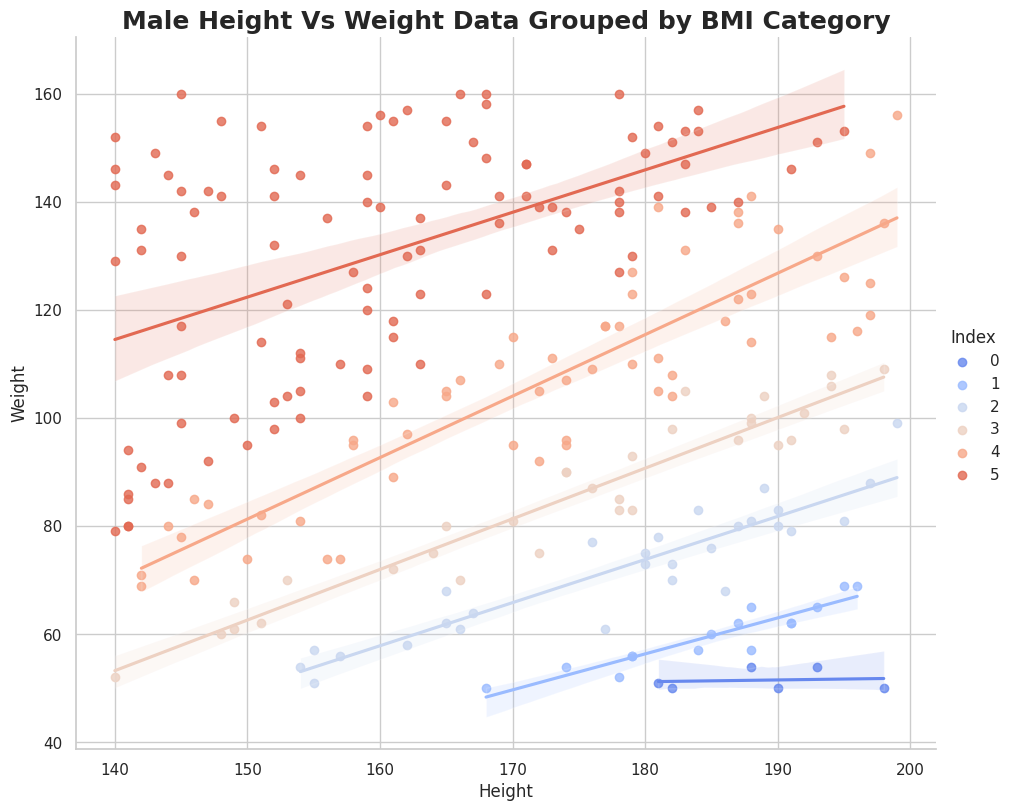

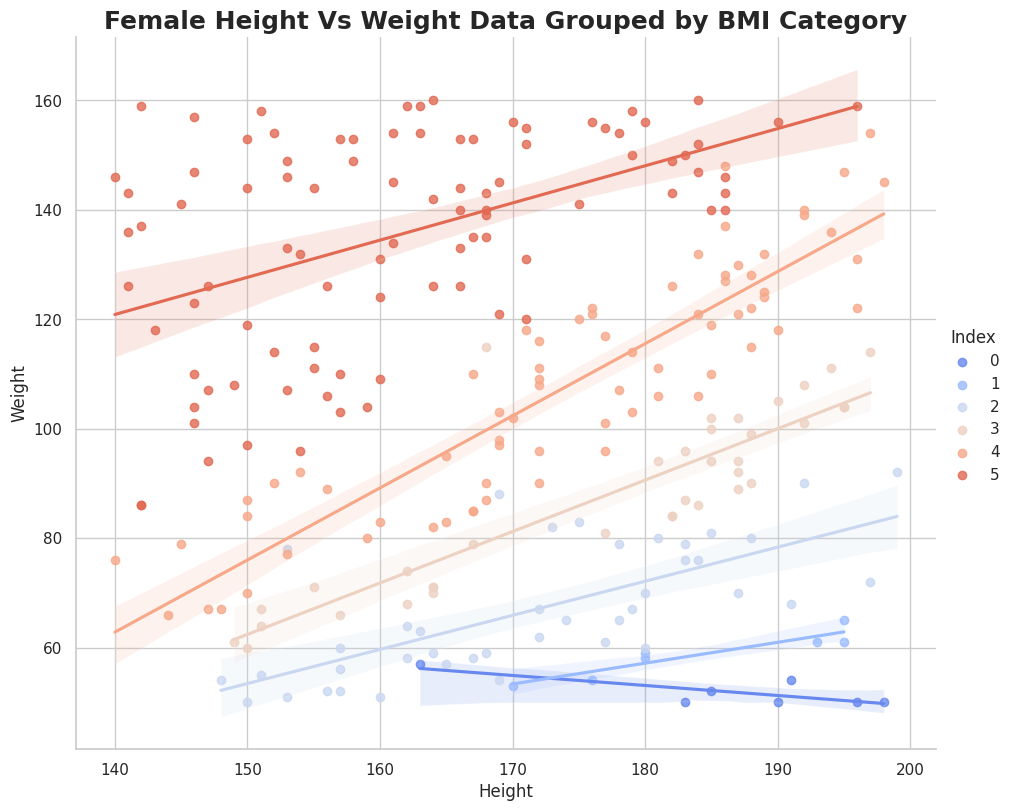

In [25]:
male_data = df[df['Gender'] == 'Male']
female_data = df[df['Gender'] == 'Female']

sns.lmplot(x='Height', y='Weight', hue='Index', data=male_data,
           fit_reg=True, height=8, aspect=1.2, palette='coolwarm')
ax = plt.gca()
ax.set_title("Male Height Vs Weight Data Grouped by BMI Category", fontsize=18, fontweight='bold')

sns.lmplot(x='Height', y='Weight', hue='Index', data=female_data,
           fit_reg=True, height=8, aspect=1.2, palette='coolwarm')
ax = plt.gca()
ax.set_title("Female Height Vs Weight Data Grouped by BMI Category", fontsize=18, fontweight='bold')


In [26]:
# Calculate the correlation between Height, Weight, and Index for the entire dataset
correlation = df[['Height', 'Weight', 'Index']].corr()

# Print the correlation matrix
print(correlation)


          Height    Weight     Index
Height  1.000000  0.000446 -0.422223
Weight  0.000446  1.000000  0.804569
Index  -0.422223  0.804569  1.000000


In [27]:
# Calculate correlation for Male data
male_correlation = male_data[['Height', 'Weight', 'Index']].corr()
print("Male Data Correlation:")
print(male_correlation)

# Calculate correlation for Female data
female_correlation = female_data[['Height', 'Weight', 'Index']].corr()
print("Female Data Correlation:")
print(female_correlation)


Male Data Correlation:
          Height    Weight     Index
Height  1.000000 -0.026133 -0.476934
Weight -0.026133  1.000000  0.790888
Index  -0.476934  0.790888  1.000000
Female Data Correlation:
          Height    Weight     Index
Height  1.000000  0.027569 -0.362132
Weight  0.027569  1.000000  0.819280
Index  -0.362132  0.819280  1.000000


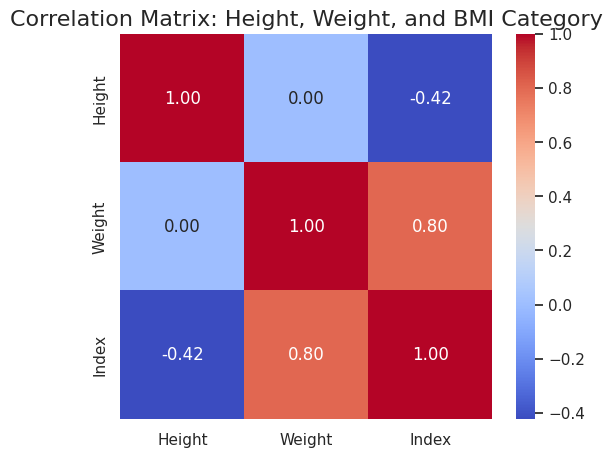

In [28]:
# Plotting the correlation matrix for the entire dataset
plt.figure(figsize=(6, 5))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f', cbar=True)
plt.title('Correlation Matrix: Height, Weight, and BMI Category', fontsize=16)
plt.show()


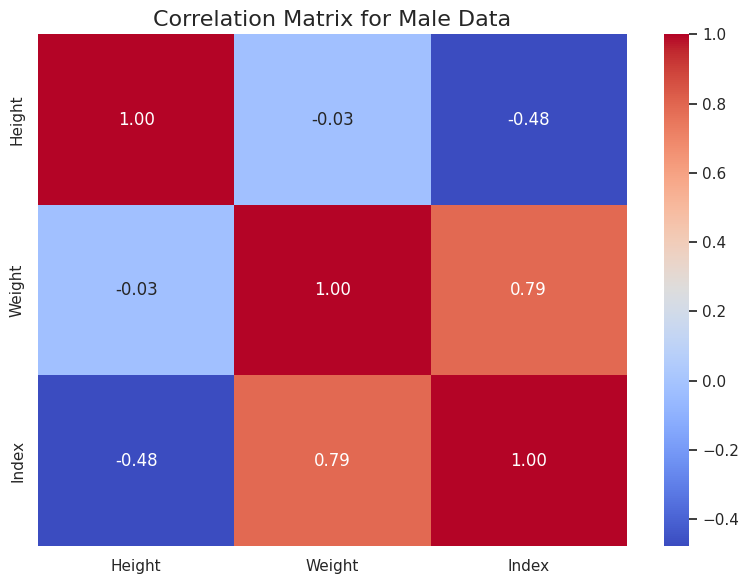

In [29]:
#Calculate correlation for Male data
male_correlation = male_data[['Height', 'Weight', 'Index']].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(male_correlation, annot=True, cmap='coolwarm', fmt='.2f', cbar=True)
plt.title('Correlation Matrix for Male Data', fontsize=16)
plt.tight_layout()
plt.show()

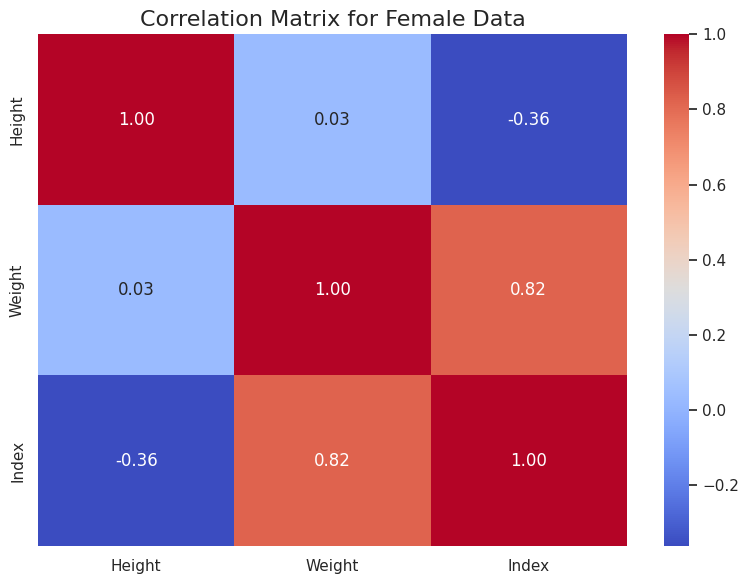

In [30]:
#Calculate correlation for Female data
female_correlation = female_data[['Height', 'Weight', 'Index']].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(female_correlation, annot=True, cmap='coolwarm', fmt='.2f', cbar=True)
plt.title('Correlation Matrix for Female Data', fontsize=16)
plt.tight_layout()
plt.show()


In [31]:
# Create an instance of LabelEncoder
label_encoder = LabelEncoder()

# Encode 'Gender' column
df['Gender'] = label_encoder.fit_transform(df['Gender'])
print(df.head())

   Gender  Height  Weight  Index
0       1     174      96      4
1       1     189      87      2
2       0     185     110      4
3       0     195     104      3
4       1     149      61      3


Here we are using label encoding to label the Male and Female to 0 and 1

In [32]:
# Displaying counts in a more readable format
index_counts = df['Index'].value_counts().sort_index()
print(index_counts)


Index
0     13
1     22
2     69
3     68
4    130
5    198
Name: count, dtype: int64


Here we can see the imbalanced Target column so we can use techniques like

*   Oversampling
*   Undersampling

*   SMOTE

Here we are using this methond in the logistic regression model inoreder to evaluate which one is best fit for the model





# Oversampling

In [33]:
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [34]:
X =df.drop('Index',axis =1)
y=df['Index']
print(X.shape)
print(y.shape)

(500, 3)
(500,)


In [35]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# Logistic Regression without oversampling
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train, y_train)
y_pred = log_reg.predict(X_test)

# Evaluate model performance without oversampling
print("Without Oversampling:")
print(f"Accuracy: {accuracy_score(y_test, y_pred)}")
print(f"Precision: {precision_score(y_test, y_pred, average='weighted')}")
print(f"Recall: {recall_score(y_test, y_pred, average='weighted')}")
print(f"F1 Score: {f1_score(y_test, y_pred, average='weighted')}")
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

Without Oversampling:
Accuracy: 0.85
Precision: 0.8686388028895768
Recall: 0.85
F1 Score: 0.8561034404192298
Confusion Matrix:
 [[ 1  0  0  0  0  0]
 [ 0  3  1  0  0  0]
 [ 0  2 14  2  0  0]
 [ 0  0  1  6  1  0]
 [ 0  0  1  4 24  1]
 [ 0  0  0  0  2 37]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       0.60      0.75      0.67         4
           2       0.82      0.78      0.80        18
           3       0.50      0.75      0.60         8
           4       0.89      0.80      0.84        30
           5       0.97      0.95      0.96        39

    accuracy                           0.85       100
   macro avg       0.80      0.84      0.81       100
weighted avg       0.87      0.85      0.86       100



/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [36]:
# Apply RandomOverSampler to oversample the minority class
oversampler = RandomOverSampler(random_state=42)
X_train_resampled, y_train_resampled = oversampler.fit_resample(X_train, y_train)

# Checking the new class distribution
print("Original class distribution in training set:")
print(y_train.value_counts())
print("\nResampled class distribution in training set:")
print(y_train_resampled.value_counts())

Original class distribution in training set:
Index
5    159
4    100
3     60
2     51
1     18
0     12
Name: count, dtype: int64

Resampled class distribution in training set:
Index
4    159
5    159
2    159
3    159
1    159
0    159
Name: count, dtype: int64


In [37]:
#Logistic Regression with oversampling
model_over = LogisticRegression(random_state=42)
model_over.fit(X_train_resampled, y_train_resampled)
y_pred_over = model_over.predict(X_test)

# Evaluate model performance with oversampling
print("\nWith Oversampling:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_over)}")
print(f"Precision: {precision_score(y_test, y_pred_over, average='weighted')}")
print(f"Recall: {recall_score(y_test, y_pred_over, average='weighted')}")
print(f"F1 Score: {f1_score(y_test, y_pred_over, average='weighted')}")
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_over))
print("Classification Report:\n", classification_report(y_test, y_pred_over))


With Oversampling:
Accuracy: 0.77
Precision: 0.8061806722689075
Recall: 0.77
F1 Score: 0.7783157538114059
Confusion Matrix:
 [[ 1  0  0  0  0  0]
 [ 0  4  0  0  0  0]
 [ 0  3 15  0  0  0]
 [ 0  0  2  6  0  0]
 [ 0  0  0  9 18  3]
 [ 0  0  0  0  6 33]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       0.57      1.00      0.73         4
           2       0.88      0.83      0.86        18
           3       0.40      0.75      0.52         8
           4       0.75      0.60      0.67        30
           5       0.92      0.85      0.88        39

    accuracy                           0.77       100
   macro avg       0.75      0.84      0.78       100
weighted avg       0.81      0.77      0.78       100



/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


# Undersampling

In [38]:
undersampler = RandomUnderSampler(random_state=42)
X_train_resampled, y_train_resampled = undersampler.fit_resample(X_train, y_train)

# Checking the new class distribution
print("Original class distribution in training set:")
print(y_train.value_counts())
print("\nResampled class distribution in training set (Undersampling):")
print(y_train_resampled.value_counts())

Original class distribution in training set:
Index
5    159
4    100
3     60
2     51
1     18
0     12
Name: count, dtype: int64

Resampled class distribution in training set (Undersampling):
Index
0    12
1    12
2    12
3    12
4    12
5    12
Name: count, dtype: int64


In [39]:
# ---------------------------- With Random Undersampling ----------------------------

# Apply RandomUnderSampler to undersample the majority class
undersampler = RandomUnderSampler(random_state=42)
X_train_resampled, y_train_resampled = undersampler.fit_resample(X_train, y_train)

# Logistic Regression with undersampling
model_over = LogisticRegression(random_state=42)
model_over.fit(X_train_resampled, y_train_resampled)
y_pred_under = model_over.predict(X_test)

# Evaluate model performance with undersampling
print("\nWith Undersampling:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_under)}")
print(f"Precision: {precision_score(y_test, y_pred_under, average='weighted')}")
print(f"Recall: {recall_score(y_test, y_pred_under, average='weighted')}")
print(f"F1 Score: {f1_score(y_test, y_pred_under, average='weighted')}")
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_under))
print("Classification Report:\n", classification_report(y_test, y_pred_under))


With Undersampling:
Accuracy: 0.74
Precision: 0.7576904761904762
Recall: 0.74
F1 Score: 0.7368923747804494
Confusion Matrix:
 [[ 1  0  0  0  0  0]
 [ 0  4  0  0  0  0]
 [ 0  3 15  0  0  0]
 [ 0  0  3  5  0  0]
 [ 0  0  2  7 15  6]
 [ 0  0  0  0  5 34]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       0.57      1.00      0.73         4
           2       0.75      0.83      0.79        18
           3       0.42      0.62      0.50         8
           4       0.75      0.50      0.60        30
           5       0.85      0.87      0.86        39

    accuracy                           0.74       100
   macro avg       0.72      0.81      0.75       100
weighted avg       0.76      0.74      0.74       100



/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


# SMOTE

In [40]:
# Apply SMOTE to generate synthetic samples for the minority class
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

# Checking the new class distribution
print("Original class distribution in training set:")
print(y_train.value_counts())
print("\nResampled class distribution in training set (SMOTE):")
print(y_train_resampled.value_counts())

Original class distribution in training set:
Index
5    159
4    100
3     60
2     51
1     18
0     12
Name: count, dtype: int64

Resampled class distribution in training set (SMOTE):
Index
4    159
5    159
2    159
3    159
1    159
0    159
Name: count, dtype: int64


In [41]:
# ---------------------------- With SMOTE ----------------------------

# Apply SMOTE to generate synthetic samples for the minority class
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

# Logistic Regression with SMOTE
model_over = LogisticRegression(random_state=42)
model_over.fit(X_train_resampled, y_train_resampled)
y_pred_smote = model_over.predict(X_test)
# Evaluate model performance with SMOTE
print("\nWith SMOTE:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_smote)}")
print(f"Precision: {precision_score(y_test, y_pred_smote, average='weighted')}")
print(f"Recall: {recall_score(y_test, y_pred_smote, average='weighted')}")
print(f"F1 Score: {f1_score(y_test, y_pred_smote, average='weighted')}")
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_smote))
print("Classification Report:\n", classification_report(y_test, y_pred_smote))



With SMOTE:
Accuracy: 0.77
Precision: 0.7956668594563331
Recall: 0.77
F1 Score: 0.7768474318474319
Confusion Matrix:
 [[ 1  0  0  0  0  0]
 [ 0  3  1  0  0  0]
 [ 0  2 16  0  0  0]
 [ 0  0  2  6  0  0]
 [ 0  0  0  8 19  3]
 [ 0  0  0  0  7 32]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       0.60      0.75      0.67         4
           2       0.84      0.89      0.86        18
           3       0.43      0.75      0.55         8
           4       0.73      0.63      0.68        30
           5       0.91      0.82      0.86        39

    accuracy                           0.77       100
   macro avg       0.75      0.81      0.77       100
weighted avg       0.80      0.77      0.78       100



/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [42]:


# Function to compute and return model performance metrics
def get_metrics(y_true, y_pred, model_name):
    report = classification_report(y_true, y_pred, output_dict=True, zero_division=0)
    return {
        'Model': model_name,
        'Accuracy': report['accuracy'],
        'F1-Score (Weighted)': report['weighted avg']['f1-score'],
        'Precision (Weighted)': report['weighted avg']['precision'],
        'Recall (Weighted)': report['weighted avg']['recall']
    }

# Collecting metrics for different resampling methods
results = [
    get_metrics(y_test, y_pred_over, 'Random Oversampling'),
    get_metrics(y_test, y_pred_under, 'Random Undersampling'),
    get_metrics(y_test, y_pred_smote, 'SMOTE')
]

# Creating a DataFrame to organize the results
df_results_sampling = pd.DataFrame(results)

# Display the table in a horizontal format for comparison
pd.set_option('display.max_columns', None)  # Show all columns
pd.set_option('display.width', 1000)  # Adjust display width for better readability

# Making text bold
print("\033[1mModel Comparison Metrics\033[0m\n")

# Printing the result table in a horizontal format
print(df_results_sampling.to_string(index=False))



Model Comparison Metrics

               Model  Accuracy  F1-Score (Weighted)  Precision (Weighted)  Recall (Weighted)
 Random Oversampling      0.77             0.778316              0.806181               0.77
Random Undersampling      0.74             0.736892              0.757690               0.74
               SMOTE      0.77             0.776847              0.795667               0.77




* SMOTE and Random Oversampling are the top-performing resampling strategies for this dataset, both yielding higher accuracy, precision, recall, and F1-scores compared to Random Undersampling.
* SMOTE stands out as an effective technique, offering balanced results similar to Random Oversampling, but with the added advantage of generating synthetic samples instead of duplicating existing ones.



# Logistic Regression
Creating 3 Logistic Regression Mode

1.   The **Generalized Dataset**, which includes all data.
2.   The **Male Dataset**, containing only data for males.

1.   The **Female Dataset**, containing only data for females.

For all models, **SMOTE** will be applied as the sampling technique, and StandardScaler will be used to standardize the height and weight features.




In [43]:
#GENERAL
X =df.drop('Index',axis =1)
y=df['Index']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [45]:
print("X train",X_train.shape)
print("y train",y_train.shape)
print("X test",X_test.shape)
print("y test",y_test.shape)

X train (400, 3)
y train (400,)
X test (100, 3)
y test (100,)


In [44]:
#CREATING MALE AND FEMALE DATAFRAME
df_male = df[df['Gender'] == 1]  # Assuming 0 represents male
df_female = df[df['Gender'] == 0]  # Assuming 1 represents female

In [46]:
X_male = df_male.drop('Index',axis=1)
y_male = df_male['Index']
print(X_male.shape)
print(y_male.shape)

(245, 3)
(245,)


In [47]:
#female
X_female = df_female.drop('Index',axis=1)
y_female = df_female['Index']
print(X_female.shape)
print(y_female.shape)

(255, 3)
(255,)


In [48]:


class_labels = ["Severely Underweight", "Underweight", "Normal", "Overweight", "Obesity", "Severely Obesity"]
results_logistic = []

def train_and_evaluate(X, y, dataset_name):
    # Split the data into training and test sets
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Adjust k_neighbors to handle small class sizes
    minority_class_size = min(y_train.value_counts())
    k_neighbors = min(5, minority_class_size - 1)  # Ensure k_neighbors < class size

    # Apply SMOTE with adjusted k_neighbors
    smote = SMOTE(random_state=42, k_neighbors=max(1, k_neighbors))
    X_train, y_train = smote.fit_resample(X_train, y_train)

    # Standardize the features
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    # Logistic Regression Model
    model = LogisticRegression(max_iter=1000)
    model.fit(X_train, y_train)

    # Predict using the trained model
    y_pred = model.predict(X_test)

    # Evaluate model performance
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='macro', zero_division=0)
    recall = recall_score(y_test, y_pred, average='macro')
    f1 = f1_score(y_test, y_pred, average='macro')

    # Print Results
    print(f"\nResults for {dataset_name} Dataset:")
    print(f"Accuracy: {accuracy}")
    print(f"Precision: {precision}")
    print(f"Recall: {recall}")
    print(f"F1 Score: {f1}")
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

    # Plot Confusion Matrix as a Heatmap
    conf_matrix = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8, 6))
    ax = sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="coolwarm",
                     xticklabels=class_labels, yticklabels=class_labels,
                     cbar_kws={'label': 'Prediction Count'},
                     annot_kws={"size": 16, 'weight': 'bold', 'color': 'black'})

    ax.set_title('Confusion Matrix', fontsize=18, fontweight='bold')
    ax.set_xlabel('Predicted Class', fontsize=14, fontweight='bold')
    ax.set_ylabel('Actual Class', fontsize=14, fontweight='bold')
    plt.xticks(rotation=45)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    # Print Classification Report
    print("Classification Report:\n", classification_report(y_test, y_pred, zero_division=0))

    # Store Results in a List
    results_logistic.append({
        'Dataset': dataset_name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    })



Results for Dataset_Without_Gender_Split Dataset:
Accuracy: 0.87
Precision: 0.6574584651674434
Recall: 0.746545584045584
F1 Score: 0.6842712842712843
Confusion Matrix:
 [[ 0  1  0  0  0  0]
 [ 0  4  0  0  0  0]
 [ 0  2 16  0  0  0]
 [ 0  0  1  7  0  0]
 [ 0  0  0  6 23  1]
 [ 0  0  0  0  2 37]]


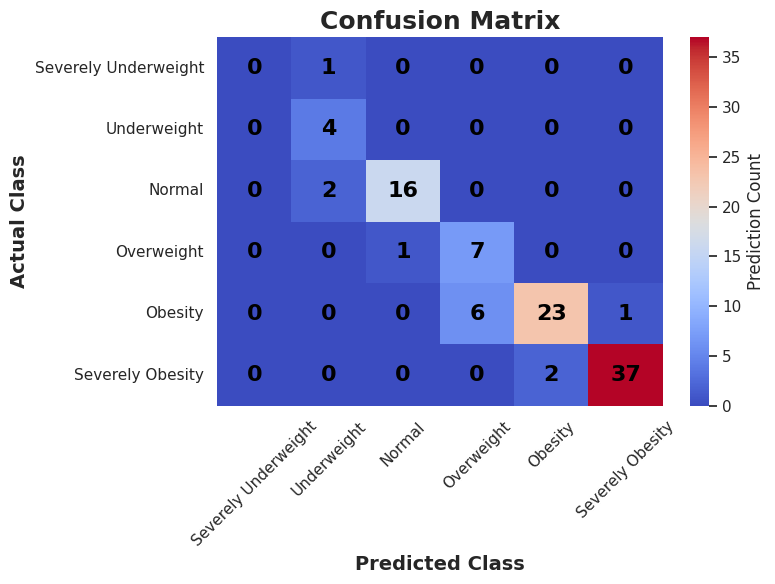

Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00         1
           1       0.57      1.00      0.73         4
           2       0.94      0.89      0.91        18
           3       0.54      0.88      0.67         8
           4       0.92      0.77      0.84        30
           5       0.97      0.95      0.96        39

    accuracy                           0.87       100
   macro avg       0.66      0.75      0.68       100
weighted avg       0.89      0.87      0.87       100



In [49]:
#General Model Logistic Regression
train_and_evaluate(X,y, "Dataset_Without_Gender_Split")


Results for Male Dataset:
Accuracy: 0.9387755102040817
Precision: 0.8833333333333333
Recall: 0.9401960784313727
F1 Score: 0.8954368243841927
Confusion Matrix:
 [[ 1  0  0  0  0  0]
 [ 1  4  0  0  0  0]
 [ 0  0  7  0  0  0]
 [ 0  0  0  9  0  0]
 [ 0  0  0  1  9  0]
 [ 0  0  0  0  1 16]]


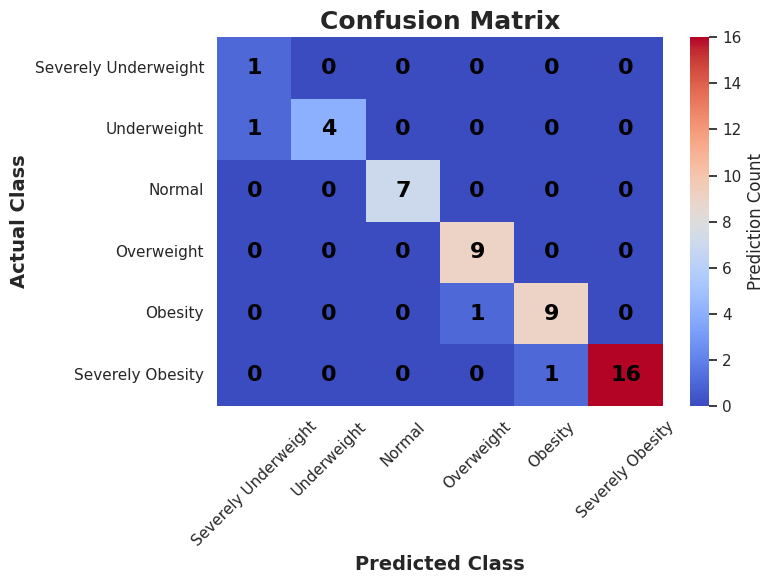

Classification Report:
               precision    recall  f1-score   support

           0       0.50      1.00      0.67         1
           1       1.00      0.80      0.89         5
           2       1.00      1.00      1.00         7
           3       0.90      1.00      0.95         9
           4       0.90      0.90      0.90        10
           5       1.00      0.94      0.97        17

    accuracy                           0.94        49
   macro avg       0.88      0.94      0.90        49
weighted avg       0.95      0.94      0.94        49



In [50]:
# Model with Male gender only
train_and_evaluate(X_male,y_male, "Male")

/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Results for Female Dataset:
Accuracy: 0.8431372549019608
Precision: 0.6181318681318682
Recall: 0.6
F1 Score: 0.6045701357466063
Confusion Matrix:
 [[ 0  0  0  0  0  0]
 [ 1  1  0  0  0  0]
 [ 0  1  3  1  1  0]
 [ 0  0  4  6  0  0]
 [ 0  0  0  0 12  0]
 [ 0  0  0  0  0 21]]


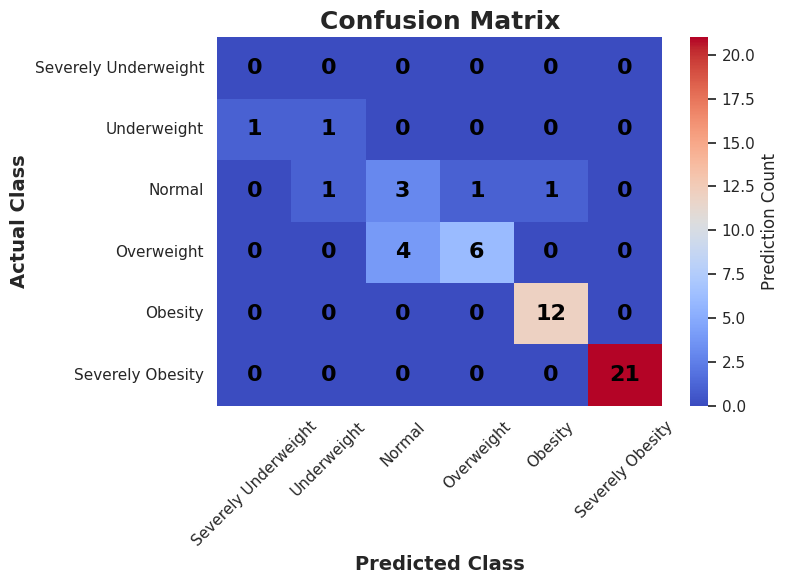

Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00         0
           1       0.50      0.50      0.50         2
           2       0.43      0.50      0.46         6
           3       0.86      0.60      0.71        10
           4       0.92      1.00      0.96        12
           5       1.00      1.00      1.00        21

    accuracy                           0.84        51
   macro avg       0.62      0.60      0.60        51
weighted avg       0.87      0.84      0.85        51



In [51]:
#Model with female gender only
train_and_evaluate(X_female,y_female, "Female")

In [52]:
#Comparison between all models
df_results_logistic_model = pd.DataFrame(results_logistic)
print("\nComparison of Results For Logistic Regression:")
df_results_logistic_model


Comparison of Results For Logistic Regression:


,Dataset,Accuracy,Precision,Recall,F1 Score
0,Dataset_Without_Gender_Split,0.870000,0.657458,0.746546,0.684271
1,Male,0.938776,0.883333,0.940196,0.895437
2,Female,0.843137,0.618132,0.600000,0.604570


# KNN (K-Nearest Neighbors)

In [53]:
# Class labels for the dataset
class_labels = ["Severely Underweight", "Underweight", "Normal", "Overweight", "Obesity", "Severely Obesity"]

# Store results for KNN
results_knn = []

def train_and_evaluate_knn(X, y, dataset_name):
    # Split the data into training and test sets
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Adjust k_neighbors to handle small class sizes
    minority_class_size = min(y_train.value_counts())
    k_neighbors = min(5, minority_class_size - 1)  # Ensure k_neighbors < class size

    # Apply SMOTE with adjusted k_neighbors
    smote = SMOTE(random_state=42, k_neighbors=max(1, k_neighbors))
    X_train, y_train = smote.fit_resample(X_train, y_train)

    # Standardize the features
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    # KNN Model
    model_knn = KNeighborsClassifier(n_neighbors=5)
    model_knn.fit(X_train, y_train)

    # Predict using the trained model
    y_pred = model_knn.predict(X_test)

    # Evaluate model performance
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='macro', zero_division=0)
    recall = recall_score(y_test, y_pred, average='macro')
    f1 = f1_score(y_test, y_pred, average='macro')

    # Print Results
    print(f"\nResults for {dataset_name} Dataset:")
    print(f"Accuracy: {accuracy}")
    print(f"Precision: {precision}")
    print(f"Recall: {recall}")
    print(f"F1 Score: {f1}")
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

    # Plot Confusion Matrix as a Heatmap
    conf_matrix = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8, 6))
    ax = sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="coolwarm",
                     xticklabels=class_labels, yticklabels=class_labels,
                     cbar_kws={'label': 'Prediction Count'},
                     annot_kws={"size": 16, 'weight': 'bold', 'color': 'black'})

    ax.set_title('Confusion Matrix', fontsize=18, fontweight='bold')
    ax.set_xlabel('Predicted Class', fontsize=14, fontweight='bold')
    ax.set_ylabel('Actual Class', fontsize=14, fontweight='bold')
    plt.xticks(rotation=45)
    plt.yticks(rotation=0)
    plt.tight_layout()

    plt.show()

    # Print Classification Report
    print("Classification Report:\n", classification_report(y_test, y_pred, zero_division=0))

    # Store Results in a List
    results_knn.append({
        'Dataset': dataset_name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    })


Results for Generalized Dataset Dataset:
Accuracy: 0.85
Precision: 0.8191415945595512
Recall: 0.8941239316239317
F1 Score: 0.8431457431457431
Confusion Matrix:
 [[ 1  0  0  0  0  0]
 [ 0  4  0  0  0  0]
 [ 0  2 15  1  0  0]
 [ 0  0  1  7  0  0]
 [ 0  0  1  5 22  2]
 [ 0  0  0  0  3 36]]


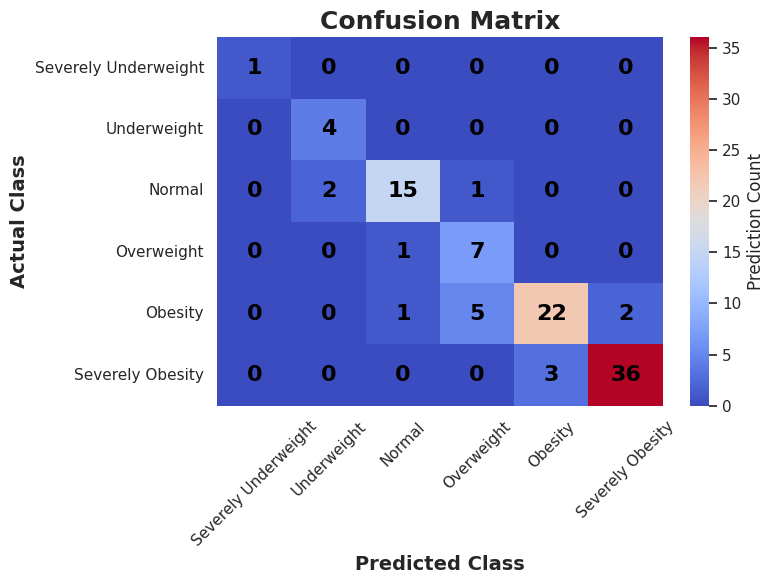

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       0.67      1.00      0.80         4
           2       0.88      0.83      0.86        18
           3       0.54      0.88      0.67         8
           4       0.88      0.73      0.80        30
           5       0.95      0.92      0.94        39

    accuracy                           0.85       100
   macro avg       0.82      0.89      0.84       100
weighted avg       0.87      0.85      0.85       100



In [54]:
#For generalized dataset
train_and_evaluate_knn(X, y, "Generalized Dataset")


Results for Male Dataset Dataset:
Accuracy: 0.8979591836734694
Precision: 0.8446969696969697
Recall: 0.9031590413943356
F1 Score: 0.8565430212489035
Confusion Matrix:
 [[ 1  0  0  0  0  0]
 [ 1  4  0  0  0  0]
 [ 0  0  7  0  0  0]
 [ 0  0  1  7  1  0]
 [ 0  0  0  1  9  0]
 [ 0  0  0  0  1 16]]


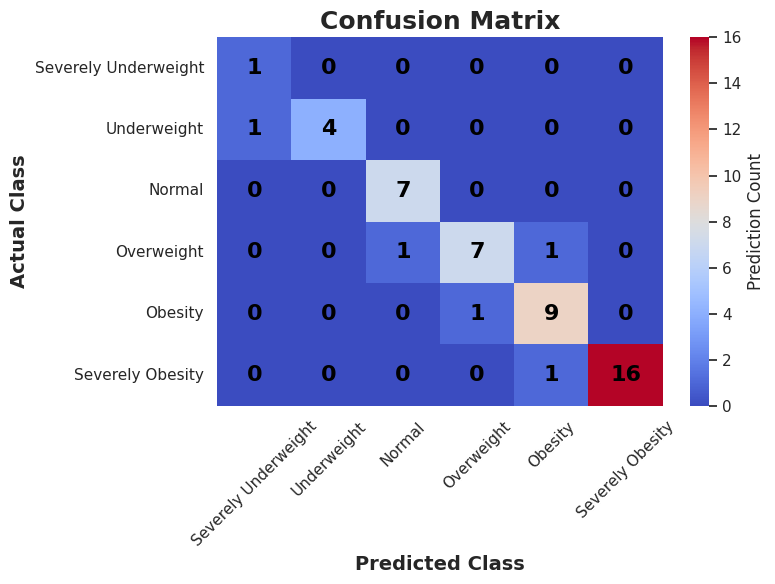

Classification Report:
               precision    recall  f1-score   support

           0       0.50      1.00      0.67         1
           1       1.00      0.80      0.89         5
           2       0.88      1.00      0.93         7
           3       0.88      0.78      0.82         9
           4       0.82      0.90      0.86        10
           5       1.00      0.94      0.97        17

    accuracy                           0.90        49
   macro avg       0.84      0.90      0.86        49
weighted avg       0.91      0.90      0.90        49



In [55]:
#for male dataset
train_and_evaluate_knn(X_male, y_male, "Male Dataset")


Results for Female Dataset Dataset:
Accuracy: 0.8823529411764706
Precision: 0.8928571428571429
Recall: 0.8771428571428572
F1 Score: 0.8703966764942376
Confusion Matrix:
 [[ 2  0  0  0  0]
 [ 0  5  0  1  0]
 [ 0  2  6  2  0]
 [ 0  0  0 12  0]
 [ 0  0  0  1 20]]


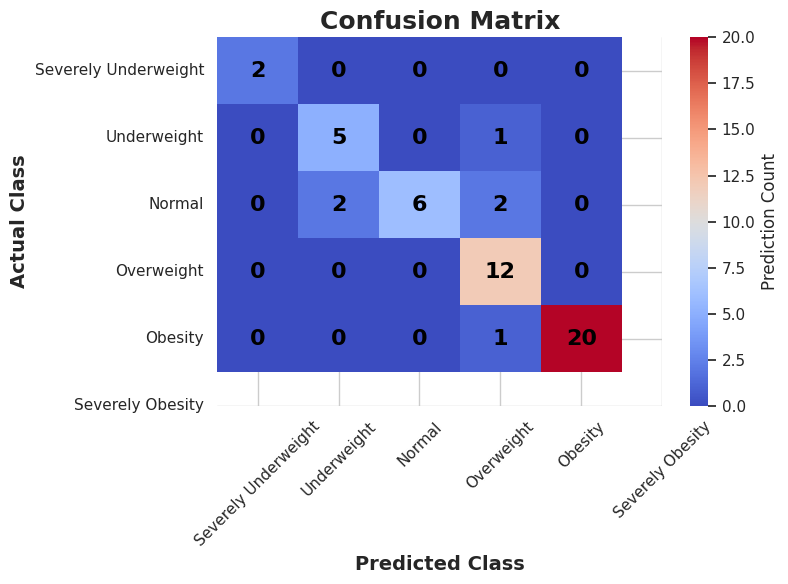

Classification Report:
               precision    recall  f1-score   support

           1       1.00      1.00      1.00         2
           2       0.71      0.83      0.77         6
           3       1.00      0.60      0.75        10
           4       0.75      1.00      0.86        12
           5       1.00      0.95      0.98        21

    accuracy                           0.88        51
   macro avg       0.89      0.88      0.87        51
weighted avg       0.91      0.88      0.88        51



In [56]:
#for female dataset
train_and_evaluate_knn(X_female, y_female, "Female Dataset")

In [ ]:
df_results_knn = pd.DataFrame(results_knn)
print("\nComparison of Results For KNN Model:")
df_results_knn


Comparison of Results For KNN Model:


,Dataset,Accuracy,Precision,Recall,F1 Score
0,Generalized Dataset,0.850000,0.819142,0.894124,0.843146
1,Male Dataset,0.897959,0.844697,0.903159,0.856543
2,Male Dataset,0.882353,0.892857,0.877143,0.870397


# Determining the best value of k for the each dataset

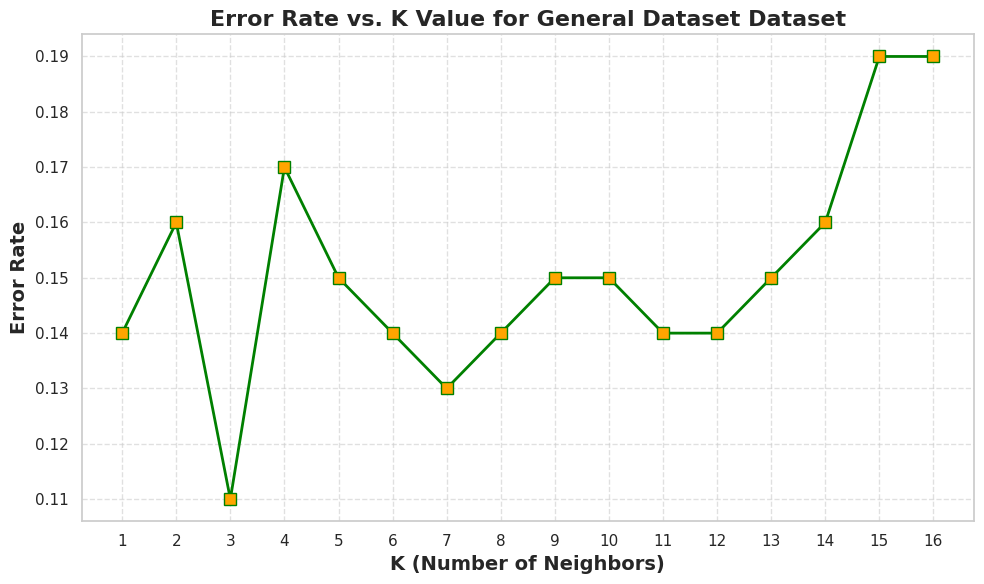

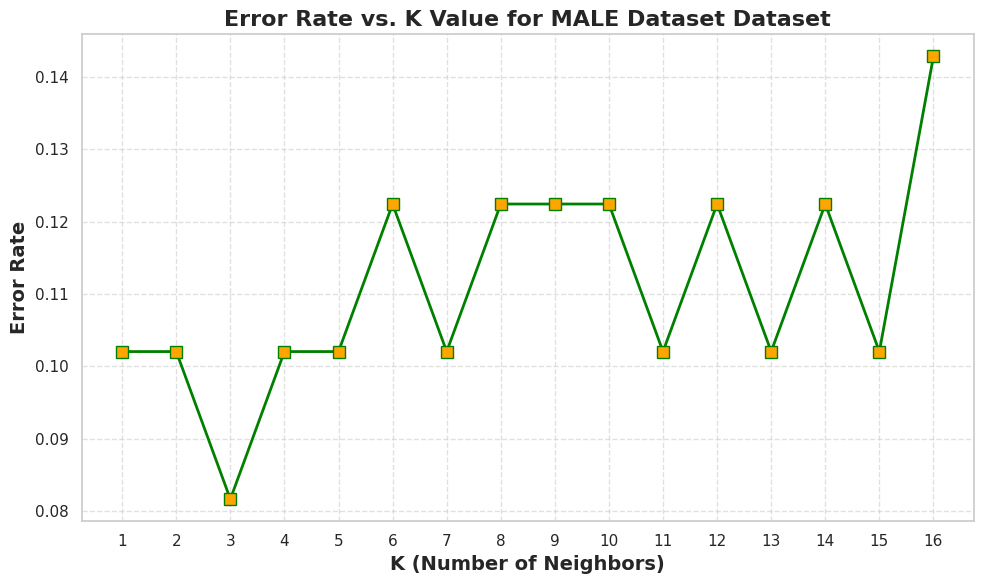

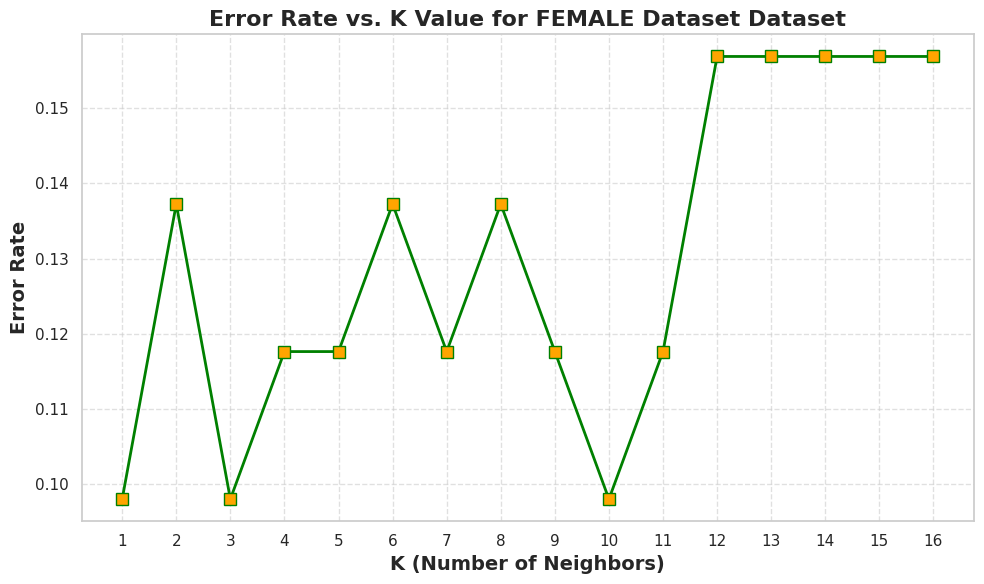

In [ ]:
def evaluate_knn_error_rate(X, y, dataset_name, k_range=16):

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    minority_class_size = min(y_train.value_counts())
    k_neighbors = min(5, minority_class_size - 1)

    # Apply SMOTE for handling class imbalance
    smote = SMOTE(random_state=42, k_neighbors=max(1, k_neighbors))
    X_train, y_train = smote.fit_resample(X_train, y_train)
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    error_rate = []

    # Iterate through different k values (from 1 to k_range)
    for i in range(1, k_range + 1):
        knn = KNeighborsClassifier(n_neighbors=i)
        knn.fit(X_train, y_train)
        pred_i = knn.predict(X_test)
        error_rate.append(np.mean(pred_i != y_test))  # Calculate the error rate

    plt.figure(figsize=(10, 6))
    plt.plot(range(1, k_range + 1), error_rate, color='green', linestyle='-', marker='s',
             markerfacecolor='orange', markersize=8, linewidth=2)

    plt.title(f'Error Rate vs. K Value for {dataset_name} Dataset', fontsize=16, fontweight='bold')
    plt.xlabel('K (Number of Neighbors)', fontsize=14, fontweight='bold')
    plt.ylabel('Error Rate', fontsize=14, fontweight='bold')
    plt.xticks(np.arange(1, k_range + 1, 1))  # Display ticks with a step of 1
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

# For combined dataset
evaluate_knn_error_rate(X, y, "General Dataset", k_range=16)

# For male dataset
evaluate_knn_error_rate(X_male, y_male, "MALE Dataset", k_range=16)

# For female dataset
evaluate_knn_error_rate(X_female, y_female, "FEMALE Dataset", k_range=16)

In [ ]:
# Class labels for the dataset
class_labels = ["Severely Underweight", "Underweight", "Normal", "Overweight", "Obesity", "Severely Obesity"]

# Store results for KNN
results_knn = []
def train_and_evaluate_knn(X, y, dataset_name, k_values):
    # Split the data into training and test sets
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Adjust k_neighbors to handle small class sizes
    minority_class_size = min(y_train.value_counts())
    k_neighbors = min(5, minority_class_size - 1)  # Ensure k_neighbors < class size

    # Apply SMOTE with adjusted k_neighbors
    smote = SMOTE(random_state=42, k_neighbors=max(1, k_neighbors))
    X_train, y_train = smote.fit_resample(X_train, y_train)
    # Standardize the features
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    # Variables to store best performance metrics
    best_k = None
    best_accuracy = -1
    best_precision = -1
    best_recall = -1
    best_f1 = -1

    # Iterate over different k values to find the best performance
    for k in k_values:
        # KNN Model with k neighbors
        model_knn = KNeighborsClassifier(n_neighbors=k)
        model_knn.fit(X_train, y_train)

        # Predict using the trained model
        y_pred = model_knn.predict(X_test)

        # Evaluate model performance
        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(y_test, y_pred, average='macro', zero_division=0)
        recall = recall_score(y_test, y_pred, average='macro')
        f1 = f1_score(y_test, y_pred, average='macro')

        # Update best performance metrics
        if accuracy > best_accuracy:
            best_accuracy = accuracy
            best_precision = precision
            best_recall = recall
            best_f1 = f1
            best_k = k

    # Print Results for the best k
    print(f"\nBest Results for {dataset_name} Dataset:")
    print(f"Best K: {best_k}")
    print(f"Accuracy: {best_accuracy}")
    print(f"Precision: {best_precision}")
    print(f"Recall: {best_recall}")
    print(f"F1 Score: {best_f1}")

    #Predict with the best k
    model_knn = KNeighborsClassifier(n_neighbors=best_k)
    model_knn.fit(X_train, y_train)
    y_pred_best = model_knn.predict(X_test)

    #Plot Confusion Matrix as a Heatmap
    conf_matrix = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8, 6))
    ax = sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="coolwarm",
                     xticklabels=class_labels, yticklabels=class_labels,
                     cbar_kws={'label': 'Prediction Count'},
                     annot_kws={"size": 16, 'weight': 'bold', 'color': 'black'})

    ax.set_title('Confusion Matrix', fontsize=18, fontweight='bold')
    ax.set_xlabel('Predicted Class', fontsize=14, fontweight='bold')
    ax.set_ylabel('Actual Class', fontsize=14, fontweight='bold')
    plt.xticks(rotation=45)
    plt.yticks(rotation=0)
    plt.tight_layout()

    plt.show()

    # Print Classification Report
    print("Classification Report:\n", classification_report(y_test, y_pred, zero_division=0))

    # Store Results in a List
    results_knn.append({
        'Dataset': dataset_name,
        'Best K': best_k,
        'Accuracy': best_accuracy,
        'Precision': best_precision,
        'Recall': best_recall,
        'F1 Score': best_f1
    })
k_values = range(1, 16)


Best Results for Generalized Dataset Dataset:
Best K: 3
Accuracy: 0.89
Precision: 0.859182098765432
Recall: 0.9150641025641026
F1 Score: 0.8790054270283137


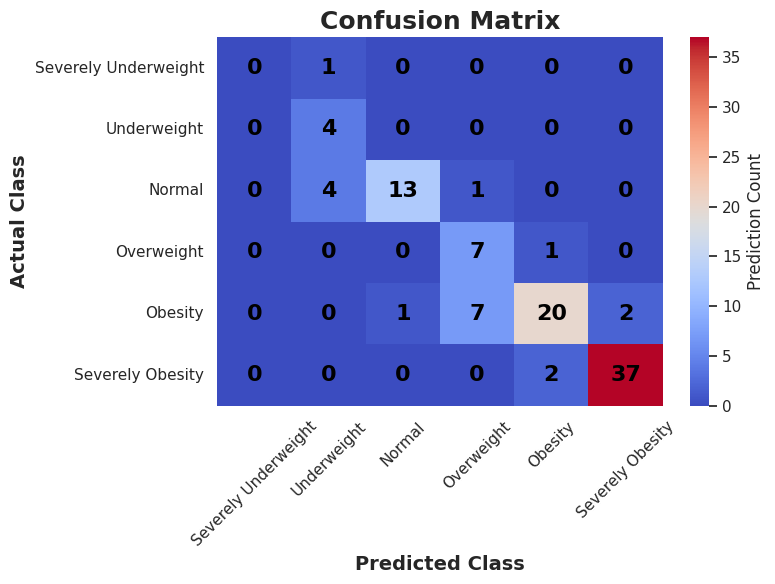

Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00         1
           1       0.44      1.00      0.62         4
           2       0.93      0.72      0.81        18
           3       0.47      0.88      0.61         8
           4       0.87      0.67      0.75        30
           5       0.95      0.95      0.95        39

    accuracy                           0.81       100
   macro avg       0.61      0.70      0.62       100
weighted avg       0.85      0.81      0.82       100



In [ ]:
#For generalized dataset (assuming you have X, y)
train_and_evaluate_knn(X, y, "Generalized Dataset", k_values)


Best Results for Male Dataset Dataset:
Best K: 3
Accuracy: 0.9183673469387755
Precision: 0.8678451178451178
Recall: 0.921677559912854
F1 Score: 0.8785473785473785


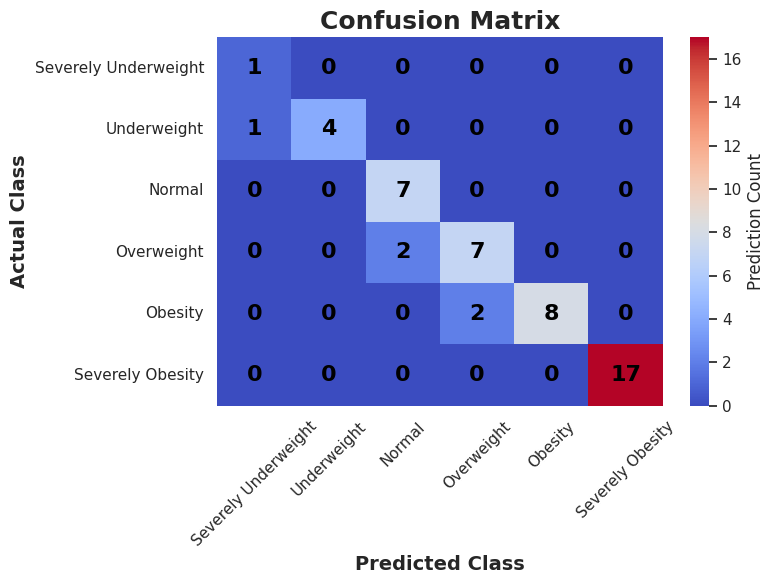

Classification Report:
               precision    recall  f1-score   support

           0       0.50      1.00      0.67         1
           1       1.00      0.80      0.89         5
           2       0.78      1.00      0.88         7
           3       0.78      0.78      0.78         9
           4       1.00      0.80      0.89        10
           5       1.00      1.00      1.00        17

    accuracy                           0.90        49
   macro avg       0.84      0.90      0.85        49
weighted avg       0.92      0.90      0.90        49



In [ ]:
#For male dataset (assuming you have X, y)
train_and_evaluate_knn(X_male, y_male, "Male Dataset", k_values)


Best Results for female Dataset Dataset:
Best K: 1
Accuracy: 0.9019607843137255
Precision: 0.8988095238095237
Recall: 0.8899999999999999
F1 Score: 0.8914529914529915


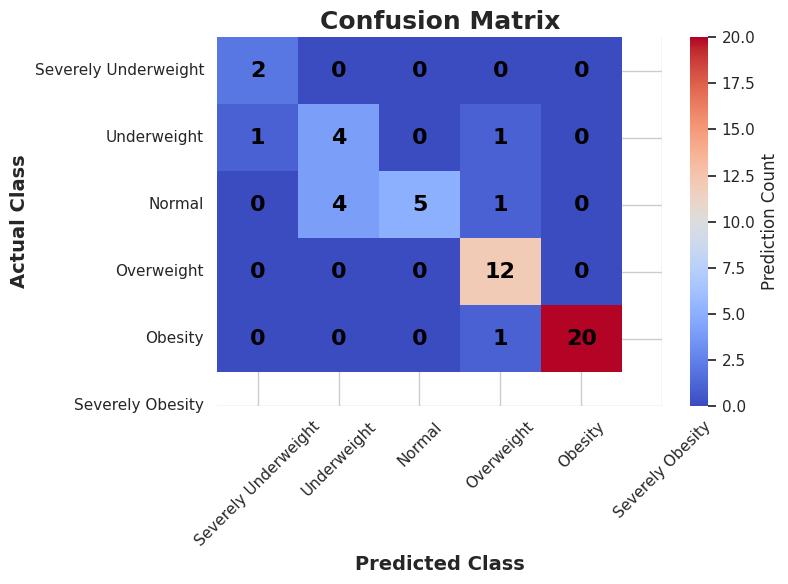

Classification Report:
               precision    recall  f1-score   support

           1       0.67      1.00      0.80         2
           2       0.50      0.67      0.57         6
           3       1.00      0.50      0.67        10
           4       0.80      1.00      0.89        12
           5       1.00      0.95      0.98        21

    accuracy                           0.84        51
   macro avg       0.79      0.82      0.78        51
weighted avg       0.88      0.84      0.84        51



In [ ]:
#For female dataset (assuming you have X, y)
train_and_evaluate_knn(X_female, y_female, "female Dataset", k_values)

In [ ]:
df_results_best_knn = pd.DataFrame(results_knn)
print("\nComparison of Results For KNN with Best K Value:")
print(df_results_best_knn)


Comparison of Results For KNN with Best K Value:
               Dataset  Best K  Accuracy  Precision    Recall  F1 Score
0  Generalized Dataset       3  0.890000   0.859182  0.915064  0.879005
1         Male Dataset       3  0.918367   0.867845  0.921678  0.878547
2       female Dataset       1  0.901961   0.898810  0.890000  0.891453




1. Adjusting k (based on dataset characteristics) results in improved performance metrics, especially in accuracy, precision, and recall across all datasets.

1.   The Male Dataset benefits the most from adjusting k, showing significant improvement in accuracy and recall.
2.   The Female Dataset benefits most in terms of precision and F1 score with the best k value, achieving higher values than the general KNN model.

1.   The Generalized Dataset shows a consistent improvement after adjusting k, although the improvements are not as dramatic as the male and female datasets.







# Support Vector Machine (SVM)

In [ ]:


class_labels = ["Severely Underweight", "Underweight", "Normal", "Overweight", "Obesity", "Severely Obesity"]

results_svm = []

def train_and_evaluate_svm(X, y, dataset_name):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    minority_class_size = min(y_train.value_counts())
    k_neighbors = min(5, minority_class_size - 1)

    smote = SMOTE(random_state=42, k_neighbors=max(1, k_neighbors))
    X_train, y_train = smote.fit_resample(X_train, y_train)

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    # Support Vector Machine (SVM)
    svm = SVC()
    svm.fit(X_train, y_train)
    y_pred = svm.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='macro', zero_division=0)
    recall = recall_score(y_test, y_pred, average='macro')
    f1 = f1_score(y_test, y_pred, average='macro')

    print(f"\nResults for {dataset_name} Dataset:")
    print(f"Accuracy: {accuracy}")
    print(f"Precision: {precision}")
    print(f"Recall: {recall}")
    print(f"F1 Score: {f1}")
    #Plot Confusion Matrix as a Heatmap
    conf_matrix = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8, 6))
    ax = sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="coolwarm",
                     xticklabels=class_labels, yticklabels=class_labels,
                     cbar_kws={'label': 'Prediction Count'},
                     annot_kws={"size": 16, 'weight': 'bold', 'color': 'black'})

    ax.set_title('Confusion Matrix', fontsize=18, fontweight='bold')
    ax.set_xlabel('Predicted Class', fontsize=14, fontweight='bold')
    ax.set_ylabel('Actual Class', fontsize=14, fontweight='bold')
    plt.xticks(rotation=45)
    plt.yticks(rotation=0)
    plt.tight_layout()

    plt.show()
    print("Classification Report:\n", classification_report(y_test, y_pred, zero_division=0))

    results_svm.append({
        'Dataset': dataset_name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    })



Results for generalized_Dataset Dataset:
Accuracy: 0.9
Precision: 0.6891078270388616
Recall: 0.7797720797720799
F1 Score: 0.7183008550107255


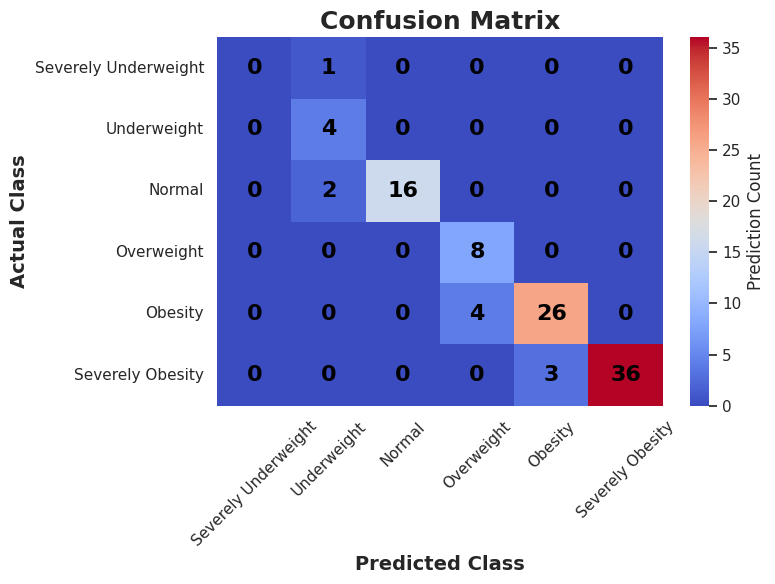

Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00         1
           1       0.57      1.00      0.73         4
           2       1.00      0.89      0.94        18
           3       0.67      1.00      0.80         8
           4       0.90      0.87      0.88        30
           5       1.00      0.92      0.96        39

    accuracy                           0.90       100
   macro avg       0.69      0.78      0.72       100
weighted avg       0.92      0.90      0.90       100



In [ ]:
#For generalized dataset (assuming you have X, y)
train_and_evaluate_svm(X, y, "generalized_Dataset")


Results for male_Dataset Dataset:
Accuracy: 0.9183673469387755
Precision: 0.8606481481481482
Recall: 0.921677559912854
F1 Score: 0.8745791245791246


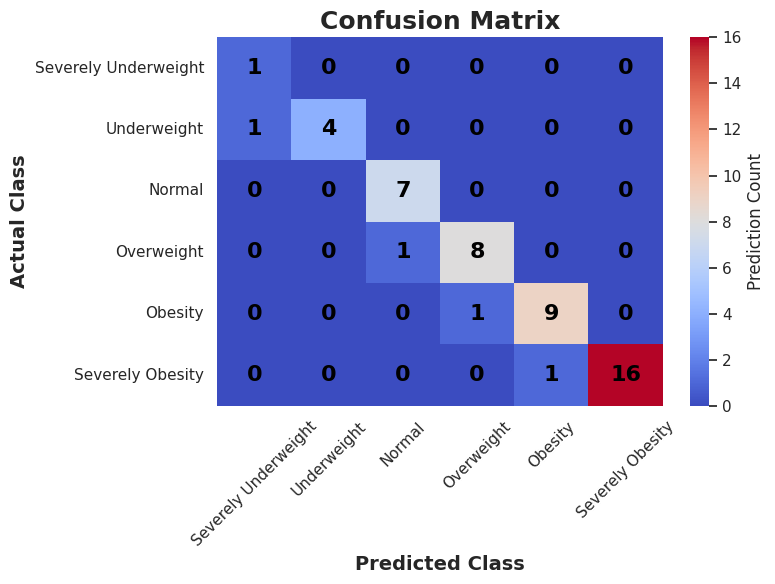

Classification Report:
               precision    recall  f1-score   support

           0       0.50      1.00      0.67         1
           1       1.00      0.80      0.89         5
           2       0.88      1.00      0.93         7
           3       0.89      0.89      0.89         9
           4       0.90      0.90      0.90        10
           5       1.00      0.94      0.97        17

    accuracy                           0.92        49
   macro avg       0.86      0.92      0.87        49
weighted avg       0.93      0.92      0.92        49



In [ ]:
#For male dataset (assuming you have X, y)
train_and_evaluate_svm(X_male, y_male, "male_Dataset")


Results for female_Dataset Dataset:
Accuracy: 0.9019607843137255
Precision: 0.8964285714285716
Recall: 0.8971428571428571
F1 Score: 0.8873003610449809


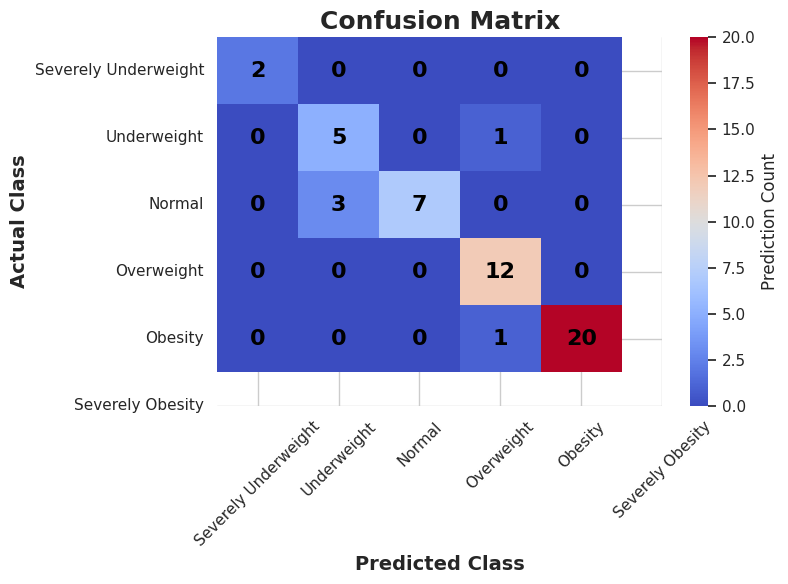

Classification Report:
               precision    recall  f1-score   support

           1       1.00      1.00      1.00         2
           2       0.62      0.83      0.71         6
           3       1.00      0.70      0.82        10
           4       0.86      1.00      0.92        12
           5       1.00      0.95      0.98        21

    accuracy                           0.90        51
   macro avg       0.90      0.90      0.89        51
weighted avg       0.92      0.90      0.90        51



In [ ]:
#For female dataset (assuming you have X, y)
train_and_evaluate_svm(X_female, y_female, "female_Dataset")

In [ ]:
df_results_svm = pd.DataFrame(results_svm)
print("\nComparison of Results For SVM:")
df_results_svm


Comparison of Results For SVM:


,Dataset,Accuracy,Precision,Recall,F1 Score
0,generalized_Dataset,0.900000,0.689108,0.779772,0.718301
1,male_Dataset,0.918367,0.860648,0.921678,0.874579
2,female_Dataset,0.901961,0.896429,0.897143,0.887300


# Hyperparameter tuning to improve the model performance here in SVM

In [ ]:
# Class labels for the dataset
class_labels = ["Severely Underweight", "Underweight", "Normal", "Overweight", "Obesity", "Severely Obesity"]

# Store results for SVM
results_svm = []

def train_and_evaluate_svm(X, y, dataset_name):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    minority_class_size = min(y_train.value_counts())
    k_neighbors = min(5, minority_class_size - 1)  # Adjust k_neighbors for SMOTE

    smote = SMOTE(random_state=42, k_neighbors=max(1, k_neighbors))
    X_train, y_train = smote.fit_resample(X_train, y_train)

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    # Define the parameter grid for SVM hyperparameters
    param_grid = {
        'C': [0.1, 1, 10, 100],  # Regularization parameter
        'kernel': ['linear', 'poly', 'rbf', 'sigmoid'],  # Kernel type
        'gamma': ['scale', 'auto'],  # Kernel coefficient
        'degree': [3, 5, 7],  # Degree for poly kernel (only used if kernel='poly')
    }

    # Create an SVM model
    svm = SVC()

    # Use GridSearchCV for hyperparameter tuning
    grid_search = GridSearchCV(svm, param_grid, cv=5, scoring='accuracy', verbose=1)
    grid_search.fit(X_train, y_train)

    # Get the best parameters and model from GridSearchCV
    best_svm = grid_search.best_estimator_

    # Predict with the best model
    y_pred = best_svm.predict(X_test)

    # Evaluate model performance
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='macro', zero_division=0)
    recall = recall_score(y_test, y_pred, average='macro')
    f1 = f1_score(y_test, y_pred, average='macro')

    print(f"\nBest Model Results for {dataset_name}:")
    print(f"Best Parameters: {grid_search.best_params_}")
    print(f"Accuracy: {accuracy}")
    print(f"Precision: {precision}")
    print(f"Recall: {recall}")
    print(f"F1 Score: {f1}")

    # Plot Confusion Matrix as a Heatmap
    conf_matrix = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8, 6))
    ax = sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="coolwarm",
                     xticklabels=class_labels, yticklabels=class_labels,
                     cbar_kws={'label': 'Prediction Count'},
                     annot_kws={"size": 16, 'weight': 'bold', 'color': 'black'})

    ax.set_title('Confusion Matrix', fontsize=18, fontweight='bold')
    ax.set_xlabel('Predicted Class', fontsize=14, fontweight='bold')
    ax.set_ylabel('Actual Class', fontsize=14, fontweight='bold')
    plt.xticks(rotation=45)
    plt.yticks(rotation=0)
    plt.tight_layout()

    plt.show()

    # Print Classification Report
    print("Classification Report:\n", classification_report(y_test, y_pred, zero_division=0))

    # Store Results in a List
    results_svm.append({
        'Dataset': dataset_name,
        'Best Parameters': grid_search.best_params_,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    })

Fitting 5 folds for each of 96 candidates, totalling 480 fits

Best Model Results for Generalized Dataset:
Best Parameters: {'C': 100, 'degree': 3, 'gamma': 'scale', 'kernel': 'rbf'}
Accuracy: 0.96
Precision: 0.924074074074074
Recall: 0.9550925925925925
F1 Score: 0.9367102396514161


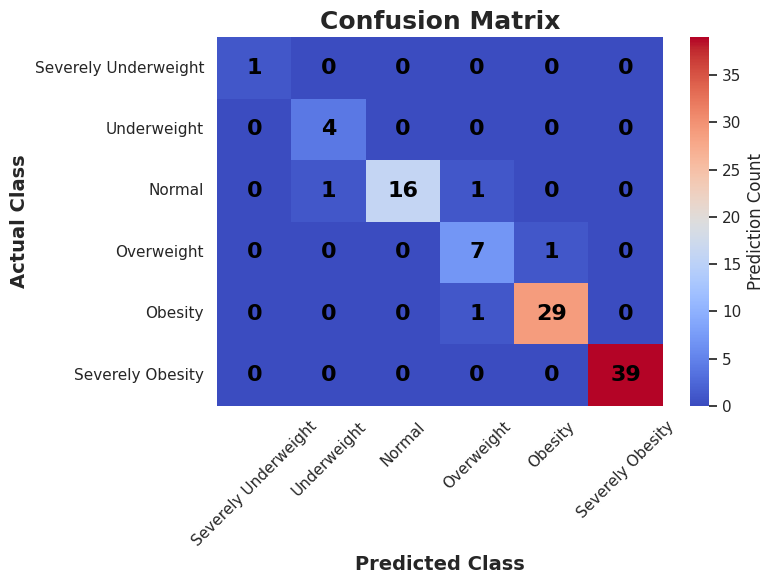

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       0.80      1.00      0.89         4
           2       1.00      0.89      0.94        18
           3       0.78      0.88      0.82         8
           4       0.97      0.97      0.97        30
           5       1.00      1.00      1.00        39

    accuracy                           0.96       100
   macro avg       0.92      0.96      0.94       100
weighted avg       0.96      0.96      0.96       100



In [ ]:
#for generalized dataset
train_and_evaluate_svm(X, y, "Generalized Dataset")

Fitting 5 folds for each of 96 candidates, totalling 480 fits

Best Model Results for Male Dataset:
Best Parameters: {'C': 100, 'degree': 3, 'gamma': 'scale', 'kernel': 'linear'}
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


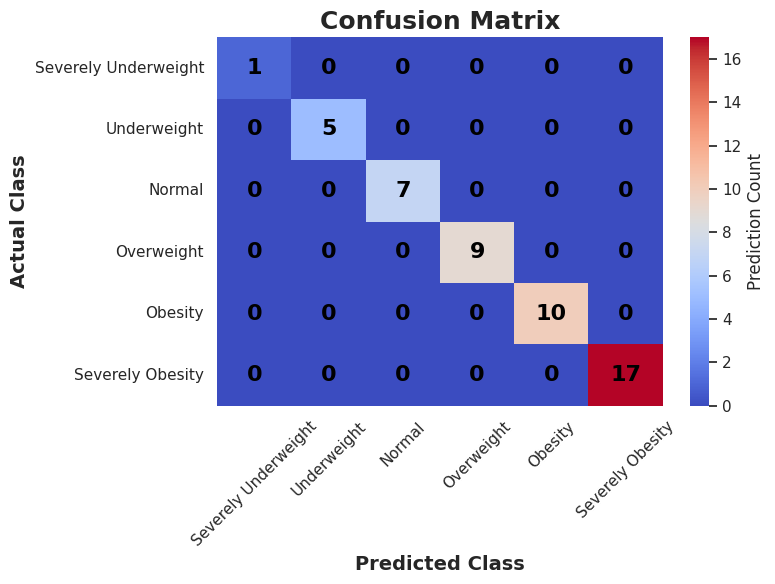

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       1.00      1.00      1.00         5
           2       1.00      1.00      1.00         7
           3       1.00      1.00      1.00         9
           4       1.00      1.00      1.00        10
           5       1.00      1.00      1.00        17

    accuracy                           1.00        49
   macro avg       1.00      1.00      1.00        49
weighted avg       1.00      1.00      1.00        49



In [ ]:
#for male dataset
train_and_evaluate_svm(X_male, y_male, "Male Dataset")

Fitting 5 folds for each of 96 candidates, totalling 480 fits

Best Model Results for Female Dataset:
Best Parameters: {'C': 100, 'degree': 3, 'gamma': 'scale', 'kernel': 'rbf'}
Accuracy: 0.9215686274509803
Precision: 0.9096153846153847
Recall: 0.9066666666666666
F1 Score: 0.899563025210084


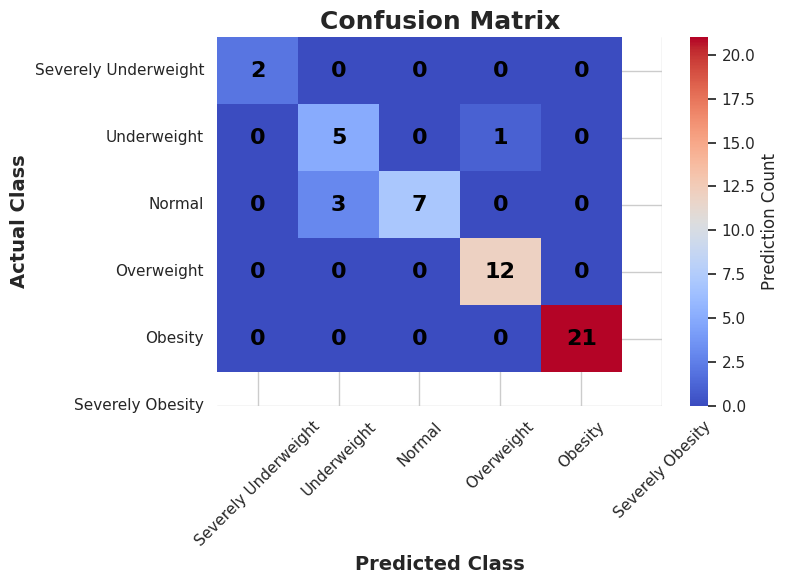

Classification Report:
               precision    recall  f1-score   support

           1       1.00      1.00      1.00         2
           2       0.62      0.83      0.71         6
           3       1.00      0.70      0.82        10
           4       0.92      1.00      0.96        12
           5       1.00      1.00      1.00        21

    accuracy                           0.92        51
   macro avg       0.91      0.91      0.90        51
weighted avg       0.94      0.92      0.92        51



In [ ]:
#for female dataset
train_and_evaluate_svm(X_female, y_female, "Female Dataset")

In [ ]:
df_results_svm = pd.DataFrame(results_svm)
print("\nComparison of Results for SVM with Hyperparameter Tuning:")
print(df_results_svm)


Comparison of Results for SVM with Hyperparameter Tuning:
               Dataset                                    Best Parameters  Accuracy  Precision    Recall  F1 Score
0  Generalized Dataset  {'C': 100, 'degree': 3, 'gamma': 'scale', 'ker...  0.960000   0.924074  0.955093  0.936710
1         Male Dataset  {'C': 100, 'degree': 3, 'gamma': 'scale', 'ker...  1.000000   1.000000  1.000000  1.000000
2       Female Dataset  {'C': 100, 'degree': 3, 'gamma': 'scale', 'ker...  0.921569   0.909615  0.906667  0.899563




*   For generalized Dataset, Hyperparameter tuning significantly improved the performance of the SVM model, showing a substantial increase in accuracy, precision, recall, and F1 score. The model's ability to generalize and classify correctly was enhanced.
*    For the Male Dataset, Hyperparameter tuning produced a perfect result with 1.0 accuracy and perfect precision, recall, and F1 score. This indicates that the tuned model is able to classify all instances perfectly, likely due to optimal parameter selection.


*  For the female Dataset, Hyperparameter tuning improved the accuracy, precision, and recall, but the improvements were more modest compared to the generalized dataset. The F1 score also showed a slight increase, indicating that the model performed more consistently.

Hyperparameter tuning led to significant improvements in the SVM model's performance across all datasets, particularly for the generalized and male datasets.


